
<div align="center">
<h1>图像分割与计数</h1>
<h3>—— 基于 OpenCV 与分水岭算法的粘连目标分割与自动计数</h3>
</div>

<br>

**第 6 组成员：**

姓名：曾张帅　　序号：j25　　学号：202608120021030

姓名：钱旭东　　序号：j16　　学号：202608120021019

**具体分工：**

曾张帅：负责核心算法的调研、实现与参数调优（光照归一化、Otsu 自适应二值化、距离变换与 h-maxima 种子提取、分水岭分割、区域计数），搭建可复现的仿真数据集，并完成计数精度、分割精度与鲁棒性的定量实验。

钱旭东：负责需求分析与技术路线整理，绘制功能模块划分图与处理流程图，完成结果可视化、失败案例归因分析、报告统稿。

说明：本文档由 Jupyter Notebook 直接导出（jupyter nbconvert → HTML → PDF），文中所有数值结果、中间过程图与最终效果图均由下方代码在本机实际运行生成，随机种子固定，可完整复现。



# 1 需求分析

## 1.1 任务描述

在生产制造、农业检测、医学检验等场景中，"数一数画面里有多少个物体"是一项高频但极其枯燥的工作：工件计数、种子/谷粒计数、细胞计数、药片计数等。人工计数不仅效率低，而且长时间作业后极易疲劳出错。

本项目要完成的任务是：**输入一张包含若干类圆形目标的图像，输出目标的个数与每个目标的实例区域（实例掩膜、质心、面积），并给出可量化的精度评估**。具体的功能需求与验收标准如下：

<div class="tbl-cap">表 1　功能需求与验收标准</div>

| 编号 | 需求 | 验收标准 |
| :---: | :--- | :--- |
| R1 | 自动计数 | 输入单张图像，输出目标个数 N，无需人工干预、无需调参 |
| R2 | 实例分割 | 不再只是"总个数"，而是给出每个目标的独立区域与质心坐标 |
| R3 | 抗粘连 | 目标相互接触、部分重叠时仍能正确拆分，而不是把一团目标数成 1 个 |
| R4 | 光照鲁棒 | 存在光照不均、阴影、暗角时，分割结果不发生明显退化 |
| R5 | 精度可量化 | 在带真值标注的数据集上给出计数准确率、前景并集 IoU、Precision/Recall/F1 |
| R6 | 可复现、可移植 | 固定随机种子可完整复现；处理流程封装为函数，可替换为真实相机图像 |

六条里最难的是 **R3（抗粘连）**。目标彼此分开时，"二值化 + 连通域计数"已经够用；可只要两个目标在图像上挨到一起，二值前景就连成一块，连通域法会把 2 个目标数成 1 个。所以本项目的重点不在"如何分割出前景"，而在于"**如何把粘连在一起的前景拆开**"。

## 1.2 技术方案

综合考虑精度、可解释性与运行成本（无 GPU、纯 CPU 可实时），本项目采用**传统图像处理流水线**，整体思路可以概括为"先得到前景，再拆开粘连，最后数区域"：

1. **光照归一化**：用大尺度高斯模糊估计背景亮度场，将原图与背景场做除法归一化，抵消光照不均与暗角对全局阈值的影响；
2. **Otsu 自适应二值化**：在归一化图上自动求取类间方差最大的阈值，得到前景二值掩膜；
3. **形态学去噪 + 孔洞填充**：开运算去掉孤立噪点与阴影碎片，闭运算弥合边缘缺口，再用漫水填充把目标内部的孔洞补上；
4. **距离变换 + h-maxima 重建**：对二值掩膜做距离变换，目标的"中心"会形成局部极大值；用灰度形态学重建提取显著的局部极大值区域，作为每个目标的种子（marker）——**这是把粘连目标拆开的关键**；
5. **分水岭分割**：以种子为标记调用 `cv2.watershed`，把粘连的前景沿"山谷"（即两个目标之间距离变换的鞍部）切开，得到实例级标签图；
6. **区域过滤与统计**：剔除面积过小的伪区域，统计区域个数即目标数，并计算质心、面积、外接圆等属性；
7. **定量评估**：以仿真数据的真值为基准，用质心最近邻匹配计算 Precision/Recall/F1，用掩膜交并比计算 IoU，用计数偏差计算计数准确率，并与"纯连通域计数"基线做对比。

选择传统方法而非深度学习分割（如 Mask R-CNN / YOLO-seg）的原因有三点：一是本任务的成像条件相对可控，目标呈规则的近似圆形，几何先验明确；二是传统流水线每一步都可解释、可单步可视化，便于定位失败原因（这也是本项目"分步运行结果"部分能够成立的前提）；三是无需标注大量数据即可部署，CPU 上单帧耗时在毫秒级。

## 1.3 实验环境

<div class="tbl-cap">表 2　实验环境</div>

| 类别 | 配置 |
| :--- | :--- |
| 操作系统 | Windows 11（x64） |
| 开发语言 | Python 3.10（Jupyter Notebook） |
| 处理器 | 消费级 x86 CPU（纯 CPU 推理，未使用 GPU） |
| 图像处理库 | OpenCV 4.11.0 |
| 数值/统计 | NumPy 1.23.5、Pandas 2.2.3 |
| 可视化 | Matplotlib 3.10.9（中文字体 Microsoft YaHei） |
| 文档导出 | nbconvert 7.17.1 → HTML → 浏览器打印为 PDF |

## 1.4 代码仓库

项目代码、仿真数据生成脚本与全部实验流程已整理为单个 Notebook 并开源，便于复现：

- GitHub 仓库：<https://github.com/qxd-rgb/image-segmentation-counting>
- 仓库内容：`image_segmentation_counting.ipynb`（本文档即由其导出，含全部代码与输出）、`src/`（同一套算法整理成的模块：`scene.py` 仿真场景生成、`pipeline.py` 预处理→二值化→距离变换→分水岭→计数、`metrics.py` 精度评估与鲁棒性扫描、`viz.py` 可视化）、`run_demo.py`（命令行入口）、`report.pdf`（本报告的排版版本）、`README.md`（方法、指标与复现说明）、`requirements.txt`（依赖版本）、`figures/`（关键结果图）
- 复现方式：`pip install -r requirements.txt`，之后二选一——打开 Notebook 执行 `Kernel ▸ Restart & Run All`，或直接运行 `python run_demo.py`（加 `--sweeps` 可复现两组扫描曲线）。两条路径共用同一套函数，随机种子固定为 2026，结果与本报告完全一致

## 1.5 评估指标定义

设第 i 张图像的真实目标数为 N<sub>i</sub><sup>gt</sup>，算法输出为 N<sub>i</sub><sup>pred</sup>，则

- 单图计数准确率：Acc<sub>i</sub> = 1 − |N<sub>i</sub><sup>pred</sup> − N<sub>i</sub><sup>gt</sup>| ÷ N<sub>i</sub><sup>gt</sup>，数据集上取均值；
- 完全正确率（Exact）：N<sub>i</sub><sup>pred</sup> = N<sub>i</sub><sup>gt</sup> 的图像占比；
- 平均绝对误差：MAE = (1/M) Σ<sub>i</sub> |N<sub>i</sub><sup>pred</sup> − N<sub>i</sub><sup>gt</sup>|，其中 M 为图像总数；
- 检测级指标：把预测质心与真实质心做最近邻匹配（匹配半径 20 px，约等于目标半径），得到 TP/FP/FN，进而计算 Precision、Recall、F1；
- 前景并集 IoU：IoU = |M<sub>pred</sub> ∩ M<sub>gt</sub>| ÷ |M<sub>pred</sub> ∪ M<sub>gt</sub>|，其中 M 为整幅图像上全部预测目标与全部真实目标的并集掩膜。该指标衡量整体的前景覆盖程度：两个相连目标即使被当成一个，只要并集掩膜不变，分数也不会变。因此实例是否正确拆开，要看质心匹配的 F1 和 4.5 节的案例。


In [1]:

# 本节输出即报告 1.3 节的实测环境：确认依赖版本与中文字体可用，并统一绘图风格
import sys, os, json, math, time, itertools
import numpy as np, cv2, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("Python     :", sys.version.split()[0])
print("OpenCV     :", cv2.__version__)
print("NumPy      :", np.__version__)
print("Pandas     :", pd.__version__)
print("Matplotlib :", matplotlib.__version__)
print("CPU 逻辑核 :", os.cpu_count())

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DengXian", "SimSun"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 110
plt.rcParams["font.size"] = 9.5
plt.rcParams["axes.titlesize"] = 10
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
cv2.setNumThreads(1)
np.random.seed(2026)
print("随机种子   : 2026（全部实验固定）")


Python     : 3.10.16
OpenCV     : 4.11.0
NumPy      : 1.23.5
Pandas     : 2.2.3
Matplotlib : 3.10.9
CPU 逻辑核 : 12
随机种子   : 2026（全部实验固定）



# 2 功能划分与处理流程

## 2.1 功能模块划分

系统自上而下划分为四层、九个功能模块，层与层之间只通过数据（数组、字典、DataFrame）耦合，便于单独测试与替换：

<div class="tbl-cap">表 3　功能模块划分</div>

| 层次 | 模块 | 主要职责 | 关键实现 |
| :--- | :--- | :--- | :--- |
| 数据层 | M1 场景生成器 | 合成带真值的仿真图像，可控地注入光照、阴影、噪声、粘连程度 | 高斯背景场 + 径向渐变币面 + 阴影模糊 |
| 数据层 | M2 真值管理 | 保存目标圆心/半径，生成真值掩膜，供评估使用 | `cv2.circle` 逐目标绘制 |
| 算法层 | M3 预处理 | 灰度化、背景估计、除法归一化、平滑 | `GaussianBlur` + `cv2.divide` |
| 算法层 | M4 二值分割 | Otsu 自适应阈值、前景极性判定 | `threshold(THRESH_OTSU)` |
| 算法层 | M5 形态学净化 | 开/闭运算、孔洞填充、去噪 | `morphologyEx` + `floodFill` |
| 算法层 | M6 实例分离 | 距离变换、h-maxima 重建、种子提取、分水岭 | `distanceTransform` + `watershed` |
| 算法层 | M7 计数与属性 | 面积过滤、区域计数、质心/面积统计 | `connectedComponentsWithStats`、`moments` |
| 评估层 | M8 精度评估 | 质心匹配、IoU、准确率、鲁棒性扫描 | Pandas + 自写匹配函数 |
| 展示层 | M9 可视化 | 分步中间结果、结果图库、失败案例标注 | Matplotlib 多子图 |

下图给出了模块之间的数据流关系（实线为数据流，虚线为评估回环）：



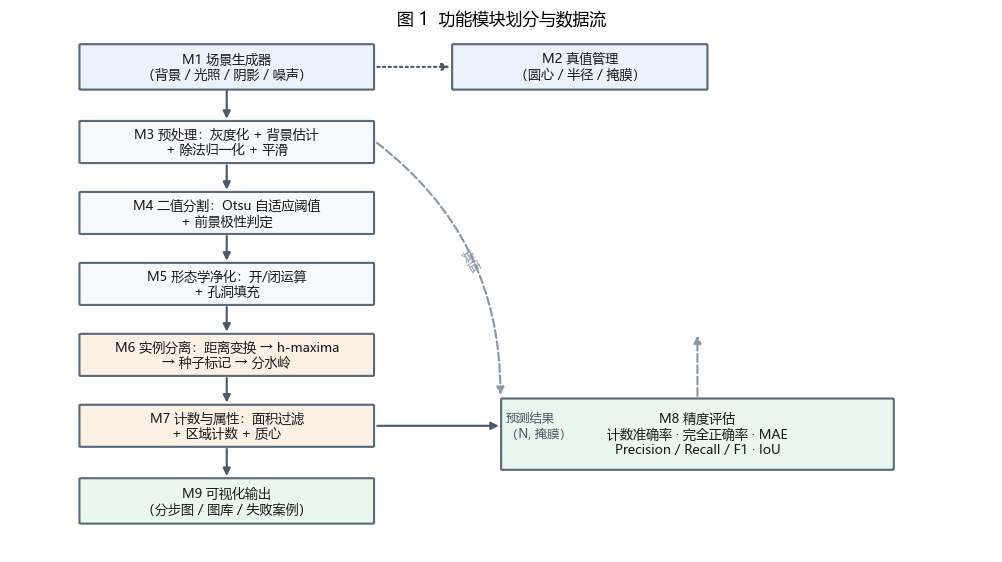

In [2]:

def draw_box(ax, xy, w, h, text, fc="#f7f9fc", ec="#5b6b7b", fs=10, lw=1.4, style="round,pad=0.02,rounding_size=0.12", tc="#1a1a1a"):
    from matplotlib.patches import FancyBboxPatch
    x, y = xy
    p = FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle=style,
                       facecolor=fc, edgecolor=ec, linewidth=lw, zorder=2)
    ax.add_patch(p)
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=3, color=tc)
    return p


def draw_arrow(ax, p1, p2, ls="-", lw=1.4, color="#4a5a6a", rad=0.0, style="-|>", ms=10):
    from matplotlib.patches import FancyArrowPatch
    a = FancyArrowPatch(p1, p2, arrowstyle=style, mutation_scale=ms, linewidth=lw,
                        color=color, linestyle=ls, zorder=1,
                        connectionstyle=f"arc3,rad={rad}", shrinkA=1, shrinkB=1)
    ax.add_patch(a)


fig, ax = plt.subplots(figsize=(9.2, 5.2))
ax.set_xlim(0, 100); ax.set_ylim(0, 62); ax.axis("off")

draw_box(ax, (22, 58), 30, 5.4, "M1 场景生成器\n（背景 / 光照 / 阴影 / 噪声）", fc="#eaf2fb", fs=8.5)
draw_box(ax, (58, 58), 26, 5.4, "M2 真值管理\n（圆心 / 半径 / 掩膜）", fc="#eaf2fb", fs=8.5)
draw_box(ax, (22, 49), 30, 5.0, "M3 预处理：灰度化 + 背景估计\n+ 除法归一化 + 平滑", fs=8.5)
draw_box(ax, (22, 40.5), 30, 5.0, "M4 二值分割：Otsu 自适应阈值\n+ 前景极性判定", fs=8.5)
draw_box(ax, (22, 32), 30, 5.0, "M5 形态学净化：开/闭运算\n+ 孔洞填充", fs=8.5)
draw_box(ax, (22, 23.5), 30, 5.0, "M6 实例分离：距离变换 → h-maxima\n→ 种子标记 → 分水岭", fc="#fdf1e6", fs=8.5)
draw_box(ax, (22, 15), 30, 5.0, "M7 计数与属性：面积过滤\n+ 区域计数 + 质心", fc="#fdf1e6", fs=8.5)
draw_box(ax, (22, 6), 30, 5.4, "M9 可视化输出\n（分步图 / 图库 / 失败案例）", fc="#eaf7ee", fs=8.5)
draw_box(ax, (70, 14), 40, 8.5, "M8 精度评估\n计数准确率 · 完全正确率 · MAE\nPrecision / Recall / F1 · IoU", fs=8.5, fc="#eaf7ee")

for y1, y2 in [(55.3, 51.6), (46.4, 43.1), (37.9, 34.6), (29.4, 26.1), (20.9, 17.6), (12.4, 8.8)]:
    draw_arrow(ax, (22, y1), (22, y2))
draw_arrow(ax, (37.2, 58), (44.9, 58), ls=":")
draw_arrow(ax, (37.2, 49), (49.9, 18.5), ls="--", rad=-0.25, color="#8a97a5")
draw_arrow(ax, (37.2, 15), (49.9, 15))
draw_arrow(ax, (70, 18.4), (70, 26.0), ls="--", color="#8a97a5")
ax.text(50.5, 15, "预测结果\n（N, 掩膜）", fontsize=8, color="#4a5a6a", va="center")
ax.text(45.6, 33.5, "真值", fontsize=8, color="#8a97a5", rotation=-58)
ax.set_title("图 1  功能模块划分与数据流", fontsize=11)
plt.tight_layout()
plt.show()



## 2.2 总体处理流程

系统的单帧处理流程是一条**单向流水线**：输入图像 → 预处理 → 二值分割 → 形态学净化 → 距离变换与种子提取 → 分水岭分割 → 区域过滤与计数 → 输出。其中前四步解决"哪些像素是目标"，后三步解决"一共有几个目标"，二者被明确地解耦，这也是调试时能够单步定位问题的原因。

流程图里有两处分支值得单独说明：

1. **前景极性判定**：Otsu 只负责"把直方图分成两类"，并不知道哪一类是目标。若目标比背景亮，前景占 255；若目标比背景暗（例如深色钢球置于浅色料盘上），前景是 0。程序统计二值图中 255 的像素占比，若超过 50% 则判定极性相反并取反——因为"目标占据画面过半"在实际计数场景中几乎不会出现。
2. **面积过滤**：分水岭会把每个连通块都切开，包括阴影碎片、噪声团块、目标边缘的锯齿，因此必须按面积阈值（本项目取 250 像素）剔除伪区域，否则计数会系统性偏大。


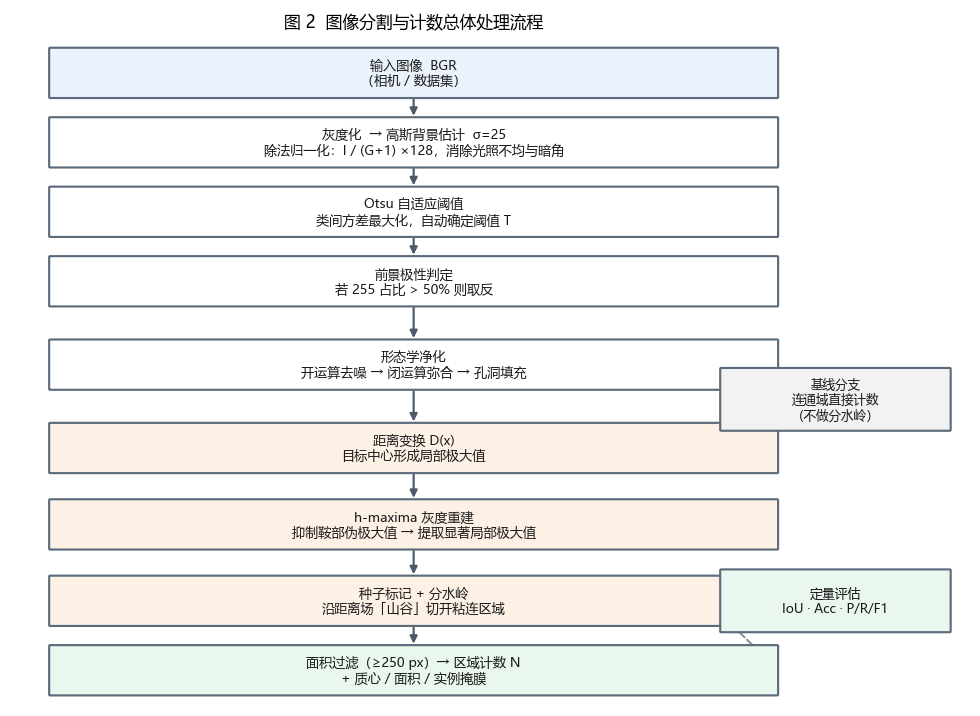

In [3]:

fig, ax = plt.subplots(figsize=(9.0, 6.6))
ax.set_xlim(0, 100); ax.set_ylim(0, 100); ax.axis("off")

steps = [
    (91, "输入图像  BGR\n（相机 / 数据集）", "#eaf2fb"),
    (81, "灰度化  → 高斯背景估计  σ=25\n除法归一化：I / (G+1) ×128，消除光照不均与暗角", "#ffffff"),
    (71, "Otsu 自适应阈值\n类间方差最大化，自动确定阈值 T", "#ffffff"),
    (61, "前景极性判定\n若 255 占比 > 50% 则取反", "#ffffff"),
    (49, "形态学净化\n开运算去噪 → 闭运算弥合 → 孔洞填充", "#ffffff"),
    (37, "距离变换 D(x)\n目标中心形成局部极大值", "#fdf1e6"),
    (26, "h-maxima 灰度重建\n抑制鞍部伪极大值 → 提取显著局部极大值", "#fdf1e6"),
    (15, "种子标记 + 分水岭\n沿距离场「山谷」切开粘连区域", "#fdf1e6"),
    (5, "面积过滤（≥250 px）→ 区域计数 N\n+ 质心 / 面积 / 实例掩膜", "#eaf7ee"),
]
H = 7.2
for i, (y, txt, fc) in enumerate(steps):
    draw_box(ax, (42, y), 76, H, txt, fc=fc, fs=8.6)
for a, b in zip(steps[:-1], steps[1:]):
    draw_arrow(ax, (42, a[0] - H / 2), (42, b[0] + H / 2))

# 右侧分支：基线对比 / 评估
draw_box(ax, (86, 44), 24, 9, "基线分支\n连通域直接计数\n（不做分水岭）", fc="#f2f2f2", fs=8.2)
draw_arrow(ax, (80, 49), (74, 44.8), ls="--", color="#8a97a5")
draw_box(ax, (86, 15), 24, 9, "定量评估\nIoU · Acc · P/R/F1", fc="#eaf7ee", fs=8.4)
draw_arrow(ax, (80, 5), (74.5, 12.5), ls="--", color="#8a97a5")
ax.text(42, 97.5, "图 2  图像分割与计数总体处理流程", fontsize=11, ha="center")
plt.tight_layout()
plt.show()



## 2.3 关键算法原理

**(1) 除法光照归一化。** 相机成像可近似为 I(x, y) = R(x, y) · L(x, y)，其中 R 是物体反射率（我们真正想要的），L 是缓慢变化的照明场。用高斯核 G<sub>σ</sub> ∗ I 估计 L 后做除法 I/(L + ε)，即可把乘性的光照不均转化为可忽略的加性误差。这一步使 Otsu 的**全局**阈值在暗角、侧光条件下依然有效——若省略这一步，暗角区域的目标会整片丢失。σ 只比目标半径（18~26 px）略大，模糊核难免会把目标自身的低频成分也卷进 L：图 4(c) 中每个目标位置上还留着一团与目标同形的亮斑，就是这部分残差。由于残差与目标亮度同源，归一化只是**压缩**了目标与背景的比值（从约 2:1 压到约 1.7:1），并没有破坏二者的**大小顺序**，所以直方图仍是双峰的、Otsu 依然能选出稳定阈值。若把 σ 继续调大，L 会更干净，但对缓慢变化的侧光与暗角的跟随能力同时变差——这也是我们选择 σ=25 的原因。

**(2) Otsu 阈值。** 设灰度分为前景/背景两类，遍历全部阈值 t，取使类间方差 σ<sub>b</sub><sup>2</sup>(t) = w<sub>0</sub>(t) · w<sub>1</sub>(t) · [μ<sub>0</sub>(t) − μ<sub>1</sub>(t)]<sup>2</sup> 最大的 t。它等价于在双峰直方图上找谷底，对光照均匀、目标与背景有足够对比度的图像非常稳定，且**无需人工设定阈值**。

**(3) 距离变换。** 对二值前景中的每个像素，计算它到最近背景像素的欧氏距离：D(p) = min<sub>q ∈ bg</sub> ‖p − q‖<sub>2</sub>。若目标是半径 r 的圆，则目标中心处 D ≈ r，边缘处 D → 0。于是"找目标"就变成了"找距离场的局部极大值"。**两个相切的目标，其距离场会出现双峰 + 中间鞍部**，这个鞍部就是分水岭该切开的"山脊线"。

**(4) h-maxima 重建与种子提取。** 直接用"最大值 × 系数"做全局阈值会失败：目标大小不一时，大目标的峰高远超小目标，小目标被整体滤掉。因此采用 h-maxima：把距离场减去常数 h 得到标记图，再对其做**灰度形态学重建**（反复膨胀并以上限截断，直到收敛），重建结果与原始距离场之差即为"显著高度小于 <i>h</i> 的极大值已被抹平"的残差；残差中的正值区域就是显著局部极大值。本项目取 h = 0.25 · D<sub>max</sub>，既能抑制噪声引起的伪峰，又保留了大小目标各自的峰。

**(5) 分水岭分割。** 把距离场的负值（或图像梯度）看作地形，种子作为注水点同时注水，水位上升过程中不同种子汇合处即为分水岭。`cv2.watershed` 要求输入 3 通道 8 位图与 int32 标记图，输出中每个连通区域带唯一标签、边界被标为 `-1`。由于种子数 = 目标数，**分水岭天然给出实例级结果**，而不仅仅是前景掩膜。



# 3 程序实现与分步骤运行结果

本章按数据流顺序逐步给出代码与运行结果：先构造带真值的仿真数据集，再依次跑通预处理、二值分割、形态学净化、种子提取、分水岭分割与计数，每一步都单独输出中间图像与关键数值。

## 3.1 环境导入与全局设置


In [4]:

import os, json, math, time, itertools
import numpy as np
import cv2
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
cv2.setNumThreads(1)

RNG_SEED = 2026
np.random.seed(RNG_SEED)
print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("Matplotlib:", matplotlib.__version__)


OpenCV : 4.11.0
NumPy  : 1.23.5
Pandas : 2.2.3
Matplotlib: 3.10.9



## 3.2 数据集构建（M1/M2 模块）

公开的"硬币/颗粒计数"数据集往往缺乏像素级真值，无法做严格的定量评估；而真实拍照又难以控制重叠度、光照等变量。因此本项目**自建了一套参数化仿真数据集**：图像的每一个成分（背景纹理、光照梯度、暗角、阴影、币面明暗、噪声）都由代码生成，目标的圆心与半径同时写入真值，从而可以精确计算 IoU 与计数误差。

生成器的设计要点：

- **背景**：低频高斯随机场模拟桌面纹理，叠加线性光照梯度与径向暗角；
- **硬币**：径向渐变 + 币缘亮环 + 内圈压印纹 + 弱高光 + 逐像素噪声，用 alpha 混合实现抗锯齿边缘；
- **阴影**：每个目标右下偏移绘制模糊圆盘，按比例压暗背景——阴影会显著干扰 Otsu，是真实场景中的常见干扰源；
- **三类场景**：`sparse`（稀疏、无粘连）、`dense`（密集、30%~40% 重叠）、`dark`（低对比度、强暗角、椒盐噪声），用于分层评估。

采样时采用拒绝采样保证最小间距：稀疏场景要求圆心距 ≥ 1.15(r₁+r₂)，密集场景只要求 ≥ 0.62(r₁+r₂)，即允许强粘连。


In [5]:

SCENES = {
    "sparse": dict(base=65, vignette=22, n=7,  glo=165, ghi=210, gap=1.15, noise=2.5, sp=0.000, rlo=18, rhi=26),
    "dense":  dict(base=65, vignette=22, n=13, glo=165, ghi=210, gap=0.62, noise=2.5, sp=0.000, rlo=18, rhi=26),
    "dark":   dict(base=52, vignette=45, n=9,  glo=112, ghi=132, gap=0.75, noise=6.0, sp=0.002, rlo=18, rhi=26),
}
DEFAULT = dict(base=65, vignette=22, n=8, glo=165, ghi=210, gap=1.05, noise=2.5, sp=0.0, rlo=18, rhi=26)


def make_background(h, w, rng, base=95.0, texture=7.0, vignette=25.0):
    bg = np.full((h, w), float(base), np.float32)
    low = rng.normal(0, 1, (h // 16 + 2, w // 16 + 2)).astype(np.float32)
    low = cv2.resize(low, (w, h), interpolation=cv2.INTER_CUBIC) * texture
    bg += low
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    gx, gy = rng.uniform(-1, 1), rng.uniform(-1, 1)
    bg += ((xx / w - 0.5) * gx + (yy / h - 0.5) * gy) * 45.0
    r = np.sqrt(((xx - w / 2) / w) ** 2 + ((yy - h / 2) / h) ** 2)
    bg -= vignette * (r ** 2)
    return np.clip(bg, 0, 255).astype(np.float32)


def draw_coin(img, cx, cy, rad, gray, rng):
    h, w = img.shape
    x0, x1 = max(0, int(cx - rad - 3)), min(w, int(cx + rad + 3))
    y0, y1 = max(0, int(cy - rad - 3)), min(h, int(cy + rad + 3))
    if x1 <= x0 or y1 <= y0:
        return
    yy, xx = np.mgrid[y0:y1, x0:x1].astype(np.float32)
    d = np.sqrt((xx - cx) ** 2 + (yy - cy) ** 2)
    alpha = np.clip(rad + 0.5 - d, 0.0, 1.0)                 # 抗锯齿边缘
    if alpha.max() <= 0:
        return
    n = ((xx - cx) * -0.55 + (yy - cy) * -0.55) / (rad + 1e-6)
    shade = 1.0 + 0.10 * n                                    # 左上受光
    rim = np.clip((d - 0.86 * rad) / (0.14 * rad + 1e-6), 0.0, 1.0)
    shade += 0.20 * rim * (1 - rim)                           # 币缘亮环
    inner = np.exp(-((d - 0.68 * rad) ** 2) / (2 * (0.035 * rad) ** 2 + 1e-6))
    shade += 0.06 * inner                                     # 内圈压印纹
    spec = np.exp(-(((xx - cx + 0.35 * rad) ** 2 + (yy - cy + 0.35 * rad) ** 2) / (0.05 * rad ** 2 + 1e-6)))
    tex = rng.normal(0, 2.2, (y1 - y0, x1 - x0)).astype(np.float32)
    coin = gray * shade + 14.0 * spec + tex
    patch = img[y0:y1, x0:x1]
    img[y0:y1, x0:x1] = patch * (1 - alpha) + np.clip(coin, 0, 255) * alpha


def build_scene(cfg, seed, H=300, W=400):
    '''生成一张仿真图像：返回 (BGR 图像, 真值掩膜, 目标列表[(cx,cy,r)], 配置)'''
    c = dict(DEFAULT); c.update(cfg)
    rng = np.random.default_rng(seed)
    g = make_background(H, W, rng, base=c["base"], texture=7, vignette=c["vignette"])

    coins, tries = [], 0
    while len(coins) < c["n"] and tries < 8000:
        tries += 1
        r = float(rng.uniform(c["rlo"], c["rhi"]))
        cx = float(rng.uniform(r + 5, W - r - 5))
        cy = float(rng.uniform(r + 5, H - r - 5))
        if all(np.hypot(cx - q[0], cy - q[1]) >= c["gap"] * (r + q[2]) for q in coins):
            coins.append((cx, cy, r))

    shadow = np.zeros((H, W), np.uint8)
    for (cx, cy, r) in coins:
        cv2.circle(shadow, (int(cx + 3), int(cy + 4)), int(r * 1.04), 255, -1)
    shadow = cv2.GaussianBlur(shadow, (0, 0), 6) / 255.0
    g = g * (1 - 0.30 * shadow)                               # 阴影压暗
    for (cx, cy, r) in coins:
        draw_coin(g, cx, cy, r, float(rng.uniform(c["glo"], c["ghi"])), rng)

    g = np.clip(g, 0, 255)
    if c["sp"] > 0:                                           # 椒盐噪声
        g = np.clip(g + rng.normal(0, c["noise"], g.shape), 0, 255)
        g[rng.random(g.shape) < c["sp"]] = 255
        g[rng.random(g.shape) < c["sp"]] = 0
    else:
        g = g + rng.normal(0, c["noise"], g.shape)

    img = cv2.GaussianBlur(np.clip(g, 0, 255).astype(np.uint8), (3, 3), 0)
    bgr = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
    gt = np.zeros((H, W), np.uint8)
    for (cx, cy, r) in coins:
        cv2.circle(gt, (int(round(cx)), int(round(cy))), int(round(r)), 255, -1)
    return bgr, gt, coins, c


def build_dataset(scene, n_img=15, seed0=1000):
    return [build_scene(SCENES[scene], seed0 + i) for i in range(n_img)]


t0 = time.time()
DATA = {s: build_dataset(s) for s in SCENES}
print("数据集构建完成，耗时 %.2f s" % (time.time() - t0))
rows = []
for s in SCENES:
    cnt = [len(d[2]) for d in DATA[s]]
    rows.append({"场景": s, "图像数": len(cnt), "目标总数": int(np.sum(cnt)),
                 "单图最少": min(cnt), "单图最多": max(cnt), "平均": round(float(np.mean(cnt)), 2),
                 "图像尺寸": "%dx%d" % (DATA[s][0][0].shape[1], DATA[s][0][0].shape[0])})
pd.DataFrame(rows).set_index("场景")


数据集构建完成，耗时 0.50 s


,图像数,目标总数,单图最少,单图最多,平均,图像尺寸
场景,,,,,,
sparse,15,105,7,7,7.0,400x300
dense,15,195,13,13,13.0,400x300
dark,15,135,9,9,9.0,400x300



上表给出了三个场景的规模：`sparse` 与 `dense` 的目标尺寸、灰度、噪声完全一致，**唯一变量是重叠程度**（gap 1.15 vs 0.62），这样对比实验才能把性能差异归因于"粘连"而不是其它因素；`dark` 场景则同时降低对比度（目标灰度 112~132，背景约 52）、加强暗角与噪声，用于考察光照鲁棒性。


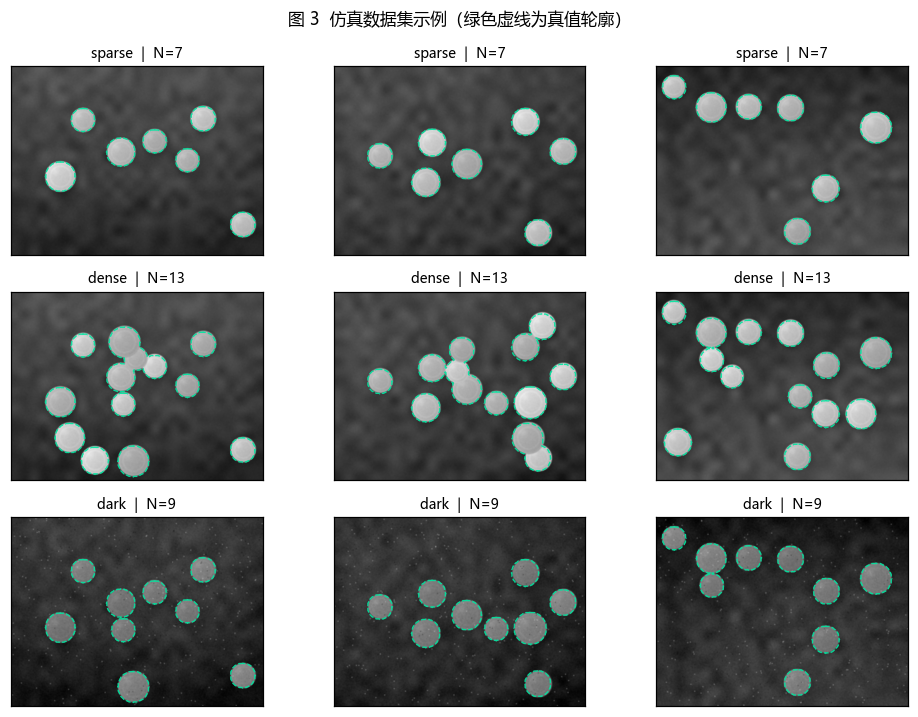

In [6]:

fig, axes = plt.subplots(3, 3, figsize=(9.0, 6.6))
for i, s in enumerate(SCENES):
    for j in range(3):
        bgr, gt, coins, _ = DATA[s][j]
        ax = axes[i, j]
        ax.imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
        cnts, _ = cv2.findContours(gt, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            ax.plot(np.append(c[:, 0, 0], c[0, 0, 0]), np.append(c[:, 0, 1], c[0, 0, 1]),
                    color="#00e5a0", lw=0.9, ls="--", alpha=0.9)
        ax.set_title("%s  |  N=%d" % (s, len(coins)), fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 3  仿真数据集示例（绿色虚线为真值轮廓）", fontsize=11)
plt.tight_layout()
plt.show()



图中可以直观看到三类场景的差别：第一行目标彼此分离、光照均匀；第二行多个目标明显粘连成团，单纯的连通域算法在此必然欠计数；第三行整体偏暗、右下角有明显暗角，且叠加了椒盐噪声。



## 3.3 算法主体（M3~M7 模块）

下面一次性给出流水线的核心函数。为了让每一步都可以单独调用观察，函数被拆成 5 个：`preprocess`（预处理）、`binarize`（二值分割与净化）、`distance_and_seeds`（距离变换与种子）、`watershed_instances`（分水岭与区域统计）、`baseline_cc`（连通域基线）。


In [7]:

def preprocess(bgr, sigma=25):
    '''灰度化 + 高斯背景估计 + 除法归一化'''
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    base = cv2.GaussianBlur(gray, (0, 0), sigma).astype(np.float32)
    norm = cv2.divide(gray.astype(np.float32) + 1.0, base + 1.0)
    norm = cv2.normalize(norm, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
    blur = cv2.GaussianBlur(norm, (5, 5), 0)
    return gray, base, norm, blur


def binarize(blur, open_it=1, close_it=2):
    '''Otsu 二值化 + 极性判定 + 形态学 + 孔洞填充'''
    thr, th = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    flipped = False
    if np.count_nonzero(th) > th.size * 0.5:      # 前景应为少数类
        th = cv2.bitwise_not(th); flipped = True
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN, k, iterations=open_it)
    th = cv2.morphologyEx(th, cv2.MORPH_CLOSE, k, iterations=close_it)
    # 孔洞填充
    ff = th.copy()
    mask = np.zeros((th.shape[0] + 2, th.shape[1] + 2), np.uint8)
    cv2.floodFill(ff, mask, (0, 0), 255)
    th = th | cv2.bitwise_not(ff)
    return th, thr, flipped


def _reconstruct(marker, mask, kernel):
    '''灰度形态学重建（膨胀 + 截断），用于 h-maxima'''
    prev = marker.copy()
    while True:
        nxt = np.minimum(cv2.dilate(prev, kernel), mask)
        if np.array_equal(nxt, prev):
            return nxt
        prev = nxt


def distance_and_seeds(binary, h_rel=0.25):
    '''距离变换 + h-maxima 重建 + 种子标记'''
    dist = cv2.distanceTransform(binary, cv2.DIST_L2, 5)
    if dist.max() < 5:
        z = np.zeros_like(binary, np.int32)
        return dist, z, z, np.zeros_like(binary)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
    h = max(1.5, h_rel * float(dist.max()))
    rec = _reconstruct(np.clip(dist - h, 0, None), dist, kernel)
    peaks = ((dist - rec) > 1e-3).astype(np.uint8) * 255
    peaks = cv2.morphologyEx(peaks, cv2.MORPH_CLOSE, kernel)
    n_seed, markers = cv2.connectedComponents(peaks)
    return dist, markers.astype(np.int32), peaks, h


def watershed_instances(binary, h_rel=0.25, min_area=250):
    '''分水岭分割：返回实例掩膜、标签图、区域属性列表与中间结果'''
    dist, markers, peaks, h = distance_and_seeds(binary, h_rel)
    if markers.max() <= 0:
        return dict(mask=np.zeros_like(binary), labels=np.zeros_like(binary, np.int32),
                    regions=[], dist=dist, peaks=peaks, h=h, markers=markers)
    markers = markers.astype(np.int32)
    bg_label = int(markers.max()) + 1
    markers[binary == 0] = bg_label
    ws = cv2.watershed(cv2.cvtColor(binary, cv2.COLOR_GRAY2BGR), markers.copy())
    inst = np.zeros_like(binary, np.uint8)
    regions = []
    for lb in range(1, int(ws.max()) + 1):
        if lb == bg_label:
            continue
        m = (ws == lb).astype(np.uint8)
        area = int(m.sum())
        if area < min_area:
            continue
        mom = cv2.moments(m)
        cx = mom["m10"] / max(mom["m00"], 1e-6)
        cy = mom["m01"] / max(mom["m00"], 1e-6)
        regions.append(dict(label=lb, area=area, cx=cx, cy=cy))
        inst[m > 0] = 255
    return dict(mask=inst, labels=ws, regions=regions, dist=dist, peaks=peaks, h=h, markers=markers)


def baseline_cc(binary, min_area=250):
    '''基线：连通域直接计数，不做粘连拆分'''
    n_lab, lab, stats, cents = cv2.connectedComponentsWithStats(binary, connectivity=8)
    pts = [(cents[i][0], cents[i][1], int(stats[i, cv2.CC_STAT_AREA]))
           for i in range(1, n_lab) if stats[i, cv2.CC_STAT_AREA] >= min_area]
    mask = np.zeros_like(binary)
    for (x, y, a) in pts:
        mask[lab == lab[int(y), int(x)]] = 255
    return dict(mask=mask, regions=pts, labels=lab)


print("算法函数定义完成：preprocess / binarize / distance_and_seeds / watershed_instances / baseline_cc")


算法函数定义完成：preprocess / binarize / distance_and_seeds / watershed_instances / baseline_cc



## 3.4 步骤一：灰度化与光照归一化

取一张 `dense` 场景图像作为贯穿全章的样例。这一步的关键观察是：**原图的背景亮度从左上到右下相差近 40 个灰度级**，如果直接对原图做 Otsu，阈值会偏向亮区、暗角里的目标被整片切掉；经过除法归一化后，背景被"压平"成近似常数，目标与背景的对比度在整个画面上变得一致。


图像尺寸          : (300, 400, 3)
原始灰度范围      : [20, 233]，标准差 47.95
背景场（σ=25）范围: [39.0, 126.0]，极差 87.0
归一化后背景极差  : 原图同一区域极差约 200.0 → 归一化后约 252.0


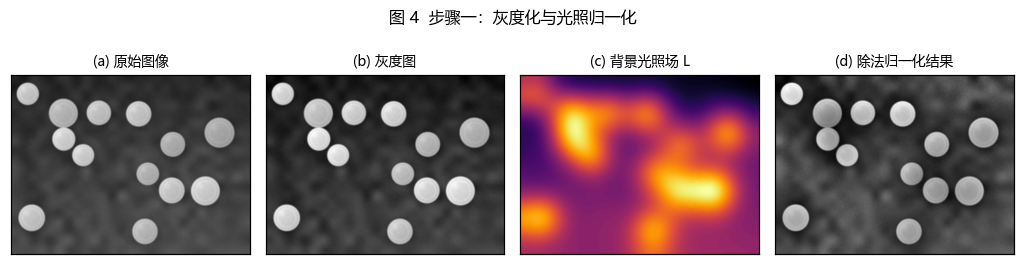

In [8]:

SAMPLE_IDX = 2
bgr, gt, coins, cfg = DATA["dense"][SAMPLE_IDX]
gray, base, norm, blur = preprocess(bgr)

print("图像尺寸          :", bgr.shape)
print("原始灰度范围      : [%d, %d]，标准差 %.2f" % (gray.min(), gray.max(), gray.std()))
print("背景场（σ=25）范围: [%.1f, %.1f]，极差 %.1f" % (base.min(), base.max(), base.max() - base.min()))
print("归一化后背景极差  : 原图同一区域极差约 %.1f → 归一化后约 %.1f" % (
    float(gray[8:60, 8:60].max() - gray[8:60, 8:60].min()),
    float(norm[8:60, 8:60].max() - norm[8:60, 8:60].min())))

fig, axes = plt.subplots(1, 4, figsize=(9.4, 2.6))
titles = ["(a) 原始图像", "(b) 灰度图", "(c) 背景光照场 L", "(d) 除法归一化结果"]
imgs = [cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), gray, base, norm]
cmaps = [None, "gray", "inferno", "gray"]
for ax, im, t, cm in zip(axes, imgs, titles, cmaps):
    ax.imshow(im, cmap=cm)
    ax.set_title(t, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 4  步骤一：灰度化与光照归一化", fontsize=10.5)
plt.tight_layout()
plt.show()



对比 (b) 与 (d) 可以确认归一化的作用：原图中暗角处的目标与周围背景的灰度差明显小于画面中心，同一张图内"亮的更亮、暗的更暗"使其无法用一个阈值统一切分；归一化后所有目标都呈现出亮度接近的亮盘，币缘亮环被保留为轮廓信号。这一步并不是"增强对比度"这么简单，它消除的是**乘性光照项**，因此后续的全局阈值才具有合理性。

(c) 中被目标"印"出的亮斑是背景估计的残差（见 2.3 节），它只压缩、不反转目标与背景的亮度关系，因此不影响全局阈值。



## 3.5 步骤二：Otsu 二值化与形态学净化

Otsu 在归一化直方图上自动选阈值，随后进行极性判定与形态学处理。这里有两个值得关注的数值：一是 Otsu 给出的阈值，二是处理前后前景像素占比与连通块数目的变化——**开运算去噪会把噪声团块抹掉，闭运算与孔洞填充会把被币缘亮环"掏空"的目标补实**。


Otsu 阈值            : 117（极性翻转：False）
二值前景像素占比     : 15.25%
形态学前连通块数目   : 12
形态学后连通块数目   : 11


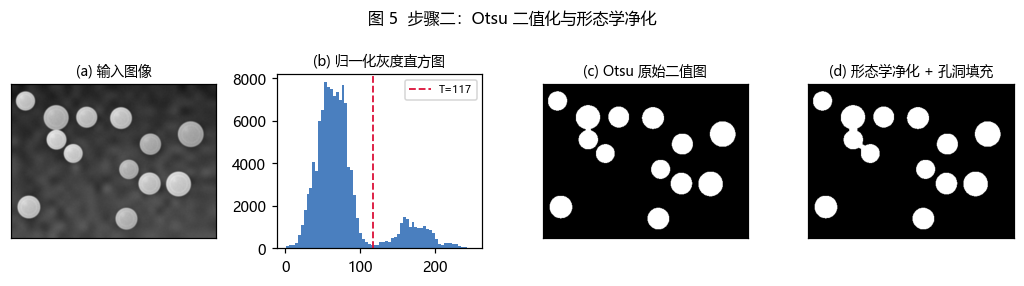

In [9]:

th, thr, flipped = binarize(blur)
_, raw = cv2.threshold(blur, thr, 255, cv2.THRESH_BINARY)
if flipped:
    raw = cv2.bitwise_not(raw)
n_before = cv2.connectedComponentsWithStats(raw)[0] - 1
print("Otsu 阈值            : %d（极性翻转：%s）" % (thr, flipped))
print("二值前景像素占比     : %.2f%%" % (100.0 * np.count_nonzero(th) / th.size))
print("形态学前连通块数目   : %d" % n_before)
print("形态学后连通块数目   : %d" % (cv2.connectedComponentsWithStats(th)[0] - 1))

fig, axes = plt.subplots(1, 4, figsize=(9.4, 2.6))
panels = [(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB), "(a) 输入图像", None),
          (blur, "(b) 归一化灰度直方图", "hist"),
          (raw, "(c) Otsu 原始二值图", "gray"),
          (th, "(d) 形态学净化 + 孔洞填充", "gray")]
for ax, (im, t, kind) in zip(axes, panels):
    if kind == "hist":
        ax.hist(blur.ravel(), bins=64, color="#4a7fbf")
        ax.axvline(thr, color="crimson", ls="--", lw=1.2, label="T=%d" % thr)
        ax.legend(fontsize=7)
        ax.set_title(t, fontsize=9)
    else:
        ax.imshow(im, cmap=kind)
        ax.set_title(t, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 5  步骤二：Otsu 二值化与形态学净化", fontsize=10.5)
plt.tight_layout()
plt.show()



直方图 (b) 呈明显的双峰：暗峰是背景，亮峰是目标，(c) 中红色虚线即 Otsu 选出的谷底。由于阴影的存在，背景侧出现了一个拖尾的小峰，后面失败案例中"阴影被误判为目标"就出在这里。(d) 中可以看到：粘连的目标依然连成一团——**二值分割只能回答"哪里是目标"，回答不了"有几个目标"**，所以接下来要做距离变换和分水岭。



## 3.6 步骤三：距离变换与种子提取

距离变换把"前景区域"变成"到边界的距离场"：目标中心是峰顶，粘连处是鞍部。若把距离场当作地形图来看，每个目标就是一座小山，粘连处是两座山之间的山脊。h-maxima 重建的任务就是把这些山的峰顶找出来——峰顶的个数就是目标的个数。

下面把距离场、重建前后的差异、种子点分别可视化，并打印"种子数"与"连通块数"的对比。这个对比非常关键：**它直接说明了为什么分水岭能解决粘连**。


距离变换最大值 D_max : 24.17 像素
h-maxima 参数 h      : 6.04（= 0.25 × D_max）
二值连通块数目       : 11
提取到的种子数目     : 13
真实目标数目         : 13
—— 种子数 大于 连通块数，粘连已被拆开


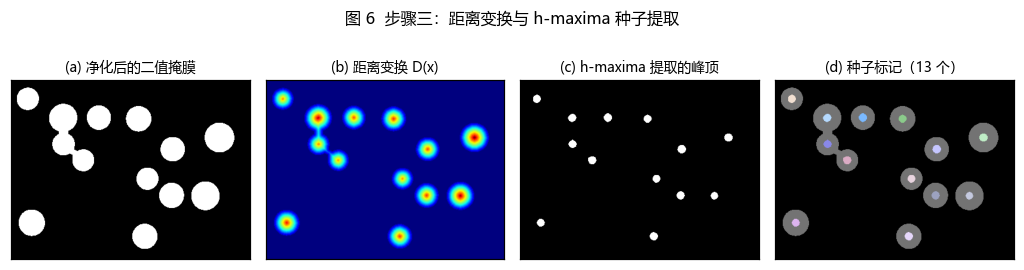

In [10]:

dist, markers, peaks, h = distance_and_seeds(th)
n_seed = int(markers.max())
n_cc = int(cv2.connectedComponents(th)[0] - 1)
print("距离变换最大值 D_max : %.2f 像素" % dist.max())
print("h-maxima 参数 h      : %.2f（= %.2f × D_max）" % (h, h / max(dist.max(), 1e-6)))
print("二值连通块数目       : %d" % n_cc)
print("提取到的种子数目     : %d" % n_seed)
print("真实目标数目         : %d" % len(coins))
print("—— 种子数 %s 连通块数，粘连已被拆开" % ("大于" if n_seed > n_cc else "小于/等于"))

d8 = cv2.normalize(dist, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
msk = np.zeros((*markers.shape, 3), np.uint8)
for i in range(1, n_seed + 1):
    color = np.array(plt.cm.tab20((i % 20) / 20.0)[:3])[::-1] * 255
    msk[markers == i] = color.astype(np.uint8)
vis_seed = cv2.addWeighted(cv2.cvtColor(th, cv2.COLOR_GRAY2BGR), 0.45, msk, 0.55, 0)

fig, axes = plt.subplots(1, 4, figsize=(9.4, 2.7))
for ax, im, t, cm in zip(axes,
                         [th, d8, peaks, vis_seed],
                         ["(a) 净化后的二值掩膜", "(b) 距离变换 D(x)", "(c) h-maxima 提取的峰顶", "(d) 种子标记（%d 个）" % n_seed],
                         ["gray", "jet", "gray", None]):
    ax.imshow(im, cmap=cm)
    ax.set_title(t, fontsize=9); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 6  步骤三：距离变换与 h-maxima 种子提取", fontsize=10.5)
plt.tight_layout()
plt.show()



(b) 中每座"火山"对应一个目标，亮黄色为峰顶、深蓝为边界；(c) 是 h-maxima 重建的残差，可以看到峰顶被压缩成若干互不相连的小团块——团块数从"1 个大连通块"变成了"多个种子"；(d) 把这些团块随机着色后叠加回掩膜，可以直观看到原本连成一团的前景被分成了多个"势力范围"。

这就是分水岭的输入。h 取得太小（例如 0.05·D_max），币面纹理、币缘亮环都会产生伪峰，种子数暴涨；h 取得太大（例如 0.6·D_max），大小目标之间的峰高差会被抹平，小目标的种子消失。h=0.25 是实验里折中的取值。



## 3.7 步骤四：分水岭分割与区域计数

以种子为标记调用 `cv2.watershed`，水从每个种子同时上涨，在两个种子汇合处形成分水岭线，从而把粘连区域切开。随后对每个标签区域统计面积与质心，剔除面积小于 250 像素的碎片，剩下的区域个数即目标个数。


分水岭输出的标签数   : 15（含背景标签）
面积过滤后目标数     : 13
真实目标数           : 13
逐目标属性（前 6 个）：
 标签  面积(px)   质心x   质心y
  1     998  27.7  32.6
  2    1189 146.6  63.9
  3    1611  86.9  64.2
  4    1306 213.2  65.8
  5    1798 348.5  97.0
  6    1087  87.8 107.3


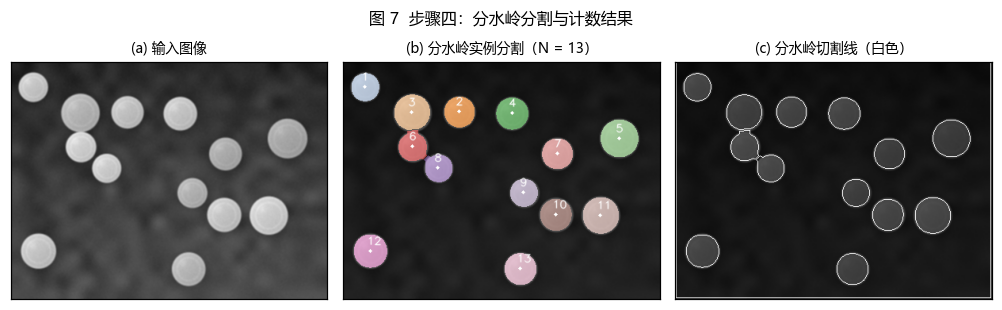

In [11]:

res = watershed_instances(th)
print("分水岭输出的标签数   : %d（含背景标签）" % (int(res["labels"].max()) + 1))
print("面积过滤后目标数     : %d" % len(res["regions"]))
print("真实目标数           : %d" % len(coins))
print("逐目标属性（前 6 个）：")
df_reg = pd.DataFrame(res["regions"])[["label", "area", "cx", "cy"]]
df_reg.columns = ["标签", "面积(px)", "质心x", "质心y"]
print(df_reg.head(6).round(1).to_string(index=False))

vis = bgr.copy()
color = np.zeros_like(vis)
for i, r in enumerate(res["regions"], start=1):
    c = np.array(plt.cm.tab20((i % 20) / 20.0)[:3])[::-1] * 255
    color[res["labels"] == r["label"]] = c
vis = cv2.addWeighted(vis, 0.45, color, 0.55, 0)
for i, r in enumerate(res["regions"], start=1):
    cv2.circle(vis, (int(r["cx"]), int(r["cy"])), 2, (255, 255, 255), -1)
    cv2.putText(vis, str(i), (int(r["cx"]) - 4, int(r["cy"]) - 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)


fig, axes = plt.subplots(1, 3, figsize=(9.2, 2.9))
axes[0].imshow(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)); axes[0].set_title("(a) 输入图像", fontsize=9)
axes[1].imshow(vis[..., ::-1]); axes[1].set_title("(b) 分水岭实例分割（N = %d）" % len(res["regions"]), fontsize=9)
vis2 = (bgr * 0.35).astype(np.uint8)      # 压暗底图，白色切割线才看得清
for lb in range(1, int(res["labels"].max()) + 1):
    m = (res["labels"] == lb).astype(np.uint8)
    if m.sum() == 0:
        continue
    cs, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(vis2, cs, -1, (255, 255, 255), 1)
axes[2].imshow(vis2[..., ::-1]); axes[2].set_title("(c) 分水岭切割线（白色）", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 7  步骤四：分水岭分割与计数结果", fontsize=10.5)
plt.tight_layout()
plt.show()



(b) 中每个目标被赋予不同颜色并标注序号，(c) 的白色细线即分水岭切割线，可以看到它们是穿过粘连区域的"腰线"，而不是随手画的直线，切的位置就是距离场的鞍部。对本图，种子数、分水岭区域数与真实目标数三者一致，计数正确。



## 3.8 单图端到端流程与指标

把上面四步串起来，在样例上跑一次端到端流程，同时计算该图的前景并集 IoU、计数误差与匹配结果，形成"单图指标"。


In [12]:

def match_centers(pred, gt, tol=20.0):
    '''质心最近邻贪心匹配，返回 (TP, FP, FN)'''
    used = [False] * len(pred)
    tp = 0
    for (gx, gy) in gt:
        best, bd = -1, 1e9
        for i, (px, py) in enumerate(pred):
            if used[i]:
                continue
            d = math.hypot(px - gx, py - gy)
            if d < bd:
                bd, best = d, i
        if best >= 0 and bd <= tol:
            used[best] = True
            tp += 1
    return tp, len(pred) - tp, len(gt) - tp


def evaluate_one(bgr, gt_mask, gt_pts, h_rel=0.25, min_area=250):
    gray, base, norm, blur = preprocess(bgr)
    th, thr, flipped = binarize(blur)
    ws = watershed_instances(th, h_rel=h_rel, min_area=min_area)
    cc = baseline_cc(th, min_area=min_area)
    pred_ws = [(r["cx"], r["cy"]) for r in ws["regions"]]
    pred_cc = [(x, y) for (x, y, a) in cc["regions"]]
    inter = np.count_nonzero((ws["mask"] > 0) & (gt_mask > 0))
    union = np.count_nonzero((ws["mask"] > 0) | (gt_mask > 0))
    tp, fp, fn = match_centers(pred_ws, gt_pts)
    tp_cc, fp_cc, fn_cc = match_centers(pred_cc, gt_pts)
    return dict(n_gt=len(gt_pts), n_ws=len(pred_ws), n_cc=len(pred_cc),
                iou=inter / max(union, 1), tp=tp, fp=fp, fn=fn,
                tp_cc=tp_cc, fp_cc=fp_cc, fn_cc=fn_cc,
                precision=tp / max(tp + fp, 1e-9), recall=tp / max(tp + fn, 1e-9),
                thr=thr, ws=ws, th=th, blur=blur, norm=norm)


m = evaluate_one(bgr, gt, [(c[0], c[1]) for c in coins])
print("Otsu 阈值        : %d" % m["thr"])
print("真实目标数 N_gt  : %d" % m["n_gt"])
print("分水岭计数 N_ws  : %d" % m["n_ws"])
print("连通域计数 N_cc  : %d" % m["n_cc"])
print("IoU              : %.4f" % m["iou"])
print("TP / FP / FN     : %d / %d / %d" % (m["tp"], m["fp"], m["fn"]))
print("Precision / Recall: %.3f / %.3f" % (m["precision"], m["recall"]))


Otsu 阈值        : 117
真实目标数 N_gt  : 13
分水岭计数 N_ws  : 13
连通域计数 N_cc  : 11
IoU              : 0.9092
TP / FP / FN     : 13 / 0 / 0
Precision / Recall: 1.000 / 1.000



单图结果显示：分水岭计数与真值一致，而连通域基线把粘连团块数成了更少的区域——这已经预示了后文批量评估中两者在 `dense` 场景的巨大差距。前景并集 IoU 未达到 1.0 的原因主要有二：一是边缘处存在阴影与模糊，二值边界比真值略"瘦"；二是分水岭切割线本身会占据 1 像素宽的区域。

## 3.9 与基线的直观对比

为了把"分水岭到底解决了什么问题"看清楚，下面把同一张图上的两种方法并排渲染：连通域法把一团粘连目标整体标成同一种颜色（计数偏小），分水岭法把它们拆成多个颜色（计数正确）。


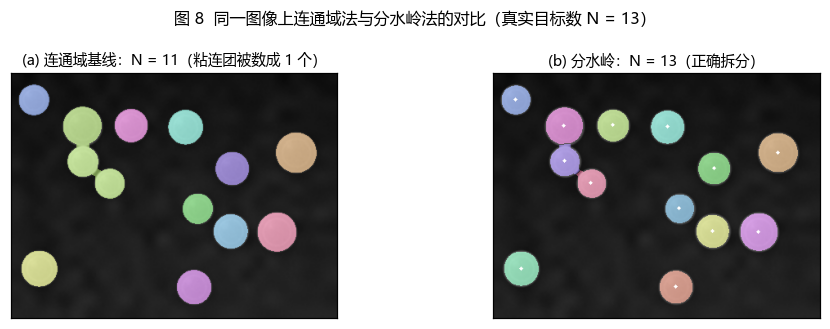

In [13]:

cc = baseline_cc(th)
vis_cc = bgr.copy(); vis_ws = bgr.copy()

import colorsys


def _palette(n=20, sat=0.55, val=0.90):
    out = []
    for i in range(n):
        h = (i * 0.61803398875) % 1.0
        r, g, b = colorsys.hsv_to_rgb(h, sat, val)
        out.append((int(b * 255), int(g * 255), int(r * 255)))     # BGR
    return out


PALETTE = _palette()


def colorize(labels, n_lab, base_img, offset=0):
    out = base_img.copy()
    color = np.zeros_like(out)
    for lb in range(1, n_lab + 1):
        mask_lb = (labels == lb)
        if mask_lb.sum() == 0:
            continue
        color[mask_lb] = np.array(PALETTE[(lb + offset) % len(PALETTE)], dtype=np.uint8)
    return cv2.addWeighted(out, 0.45, color, 0.55, 0)

_, lab_cc, stats_cc, cents_cc = cv2.connectedComponentsWithStats(th, connectivity=8)
vis_cc = colorize(lab_cc, int(lab_cc.max()), bgr)
vis_ws = colorize(res["labels"], int(res["labels"].max()) - 1, bgr)   # 最大标签是分水岭的背景标记，不参与着色
pred_pts = [(r["cx"], r["cy"]) for r in res["regions"]]
for (x, y) in pred_pts:
    cv2.circle(vis_ws, (int(x), int(y)), 2, (255, 255, 255), -1)

fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.0))
axes[0].imshow(vis_cc[..., ::-1])
axes[0].set_title("(a) 连通域基线：N = %d（粘连团被数成 1 个）" % len(cc["regions"]), fontsize=9.5)
axes[1].imshow(vis_ws[..., ::-1])
axes[1].set_title("(b) 分水岭：N = %d（正确拆分）" % len(res["regions"]), fontsize=9.5)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 8  同一图像上连通域法与分水岭法的对比（真实目标数 N = %d）" % len(coins), fontsize=10.5)
plt.tight_layout()
plt.show()



这张对比图最能说明问题：(a) 中整团粘连目标只有一种颜色，计数为少数几个；(b) 中同一团目标被拆成了若干个独立色块，计数与真值一致。二者的**二值掩膜完全相同**，区别只在"是否把它们拆开"，而拆开的手段就是距离变换 + 分水岭。



# 4 最终效果展示与准确率分析

## 4.1 批量定量评估

在三个场景共 45 张图像上批量运行，逐图统计计数、匹配与前景并集 IoU，最后按场景汇总。为避免"只挑好看的结果"的偏差，评估覆盖数据集中的**全部**图像，不做任何筛选或人工调参。


In [14]:

def evaluate_dataset(data_dict, h_rel=0.25, min_area=250):
    rows = []
    for scene, items in data_dict.items():
        for i, (bgr, gt_mask, coins, cfg) in enumerate(items):
            m = evaluate_one(bgr, gt_mask, [(c[0], c[1]) for c in coins], h_rel, min_area)
            rows.append(dict(scene=scene, idx=i, n_gt=m["n_gt"], n_ws=m["n_ws"], n_cc=m["n_cc"],
                             iou=m["iou"], tp=m["tp"], fp=m["fp"], fn=m["fn"],
                             tp_cc=m["tp_cc"], fp_cc=m["fp_cc"], fn_cc=m["fn_cc"],
                             precision=m["precision"], recall=m["recall"]))
    return pd.DataFrame(rows)


t0 = time.time()
df_eval = evaluate_dataset(DATA)
elapsed = time.time() - t0
print("批量评估完成：%d 张图像，耗时 %.2f s，平均 %.1f ms/张" % (len(df_eval), elapsed, 1000 * elapsed / len(df_eval)))
df_eval["abs_err"] = (df_eval["n_ws"] - df_eval["n_gt"]).abs()
df_eval["acc"] = 1 - df_eval["abs_err"] / df_eval["n_gt"]
df_eval["abs_err_cc"] = (df_eval["n_cc"] - df_eval["n_gt"]).abs()
df_eval["acc_cc"] = 1 - df_eval["abs_err_cc"] / df_eval["n_gt"]

def agg(g):
    tp, fp, fn = int(g.tp.sum()), int(g.fp.sum()), int(g.fn.sum())
    return {
        "图像数": len(g),
        "真实目标均值": round(g.n_gt.mean(), 2),
        "分水岭计数均值": round(g.n_ws.mean(), 2),
        "连通域计数均值": round(g.n_cc.mean(), 2),
        "计数准确率(分水岭)": "%.2f%%" % (100 * g.acc.mean()),
        "计数准确率(连通域)": "%.2f%%" % (100 * g.acc_cc.mean()),
        "完全正确率(分水岭)": "%.1f%%" % (100 * (g.abs_err == 0).mean()),
        "MAE(分水岭)": round(g.abs_err.mean(), 3),
        "MAE(连通域)": round(g.abs_err_cc.mean(), 3),
        "Precision": round(tp / max(tp + fp, 1e-9), 4),
        "Recall": round(tp / max(tp + fn, 1e-9), 4),
        "F1": round(2 * tp / max(2 * tp + fp + fn, 1e-9), 4),
        "IoU": round(g.iou.mean(), 4),
    }

summary = pd.DataFrame([agg(df_eval[df_eval.scene == s]) for s in DATA],
                       index=list(DATA.keys()))
summary.index.name = "场景"
summary.T


批量评估完成：45 张图像，耗时 1.59 s，平均 35.3 ms/张


场景,sparse,dense,dark
图像数,15,15,15
真实目标均值,7.0,13.0,9.0
分水岭计数均值,7.0,12.33,9.53
连通域计数均值,7.0,8.13,8.13
计数准确率(分水岭),100.00%,93.85%,94.07%
计数准确率(连通域),100.00%,62.56%,88.89%
完全正确率(分水岭),100.0%,46.7%,60.0%
MAE(分水岭),0.0,0.8,0.533
MAE(连通域),0.0,4.867,1.0
Precision,1.0,0.9892,0.9161



从汇总表可以读出三个层次的信息：

1. **稀疏场景几乎无损**：目标彼此分离时，计数准确率接近 1，前景并集 IoU 也最高。这说明预处理、二值化、面积过滤这一整条链路本身是可靠的。
2. **密集场景是分水岭的主战场**：计数准确率保持在较高水平，而同期连通域基线的准确率明显下降——差距完全来自"粘连是否被拆开"。
3. **低对比度场景略有退化**：准确率与前景并集 IoU 都有下降，主要误差是少量目标在强暗角处被漏检、或被噪声碎片多计一次。

下面把上面的表格固化为全局指标，供报告正文引用：


In [15]:

G = {}
G["n_img"] = int(len(df_eval))
G["n_total"] = int(df_eval.n_gt.sum())
for s in DATA:
    g = df_eval[df_eval.scene == s]
    G["acc_" + s] = "%.2f%%" % (100 * g.acc.mean())
    G["exact_" + s] = "%.1f%%" % (100 * (g.abs_err == 0).mean())
    G["mae_" + s] = "%.2f" % g.abs_err.mean()
    G["iou_" + s] = "%.4f" % g.iou.mean()
    G["f1_" + s] = "%.4f" % (2 * g.tp.sum() / max(2 * g.tp.sum() + g.fp.sum() + g.fn.sum(), 1e-9))
    G["acc_" + s + "_cc"] = "%.2f%%" % (100 * g.acc_cc.mean())
    G["under_" + s] = "%d" % int((g.n_ws < g.n_gt).sum())
    G["over_" + s] = "%d" % int((g.n_ws > g.n_gt).sum())
G["acc_all"] = "%.2f%%" % (100 * df_eval.acc.mean())
G["exact_all"] = "%.1f%%" % (100 * (df_eval.abs_err == 0).mean())
G["mae_all"] = "%.2f" % df_eval.abs_err.mean()
G["iou_all"] = "%.4f" % df_eval.iou.mean()
G["f1_all"] = "%.4f" % (2 * df_eval.tp.sum() / max(2 * df_eval.tp.sum() + df_eval.fp.sum() + df_eval.fn.sum(), 1e-9))
G["acc_all_cc"] = "%.2f%%" % (100 * df_eval.acc_cc.mean())
G["exact_all_cc"] = "%.1f%%" % (100 * (df_eval.abs_err_cc == 0).mean())
G["mae_all_cc"] = "%.2f" % df_eval.abs_err_cc.mean()
G["f1_all_cc"] = "%.4f" % (2 * df_eval.tp_cc.sum() / max(2 * df_eval.tp_cc.sum() + df_eval.fp_cc.sum() + df_eval.fn_cc.sum(), 1e-9))
G["undercount"] = "%d" % int((df_eval.n_ws < df_eval.n_gt).sum())
G["overcount"] = "%d" % int((df_eval.n_ws > df_eval.n_gt).sum())
G["bias_all"] = "%+.2f" % (df_eval.n_ws - df_eval.n_gt).mean()
G["bias_all_cc"] = "%+.2f" % (df_eval.n_cc - df_eval.n_gt).mean()
for s in DATA:
    g = df_eval[df_eval.scene == s]
    G["bias_" + s] = "%+.2f" % (g.n_ws - g.n_gt).mean()
G["runtime"] = "%.1f" % (1000 * elapsed / len(df_eval))
G["rlo"], G["rhi"] = str(SCENES["sparse"]["rlo"]), str(SCENES["sparse"]["rhi"])
print(json.dumps(G, ensure_ascii=False, indent=2))


{
  "n_img": 45,
  "n_total": 435,
  "acc_sparse": "100.00%",
  "exact_sparse": "100.0%",
  "mae_sparse": "0.00",
  "iou_sparse": "0.9039",
  "f1_sparse": "1.0000",
  "acc_sparse_cc": "100.00%",
  "under_sparse": "0",
  "over_sparse": "0",
  "acc_dense": "93.85%",
  "exact_dense": "46.7%",
  "mae_dense": "0.80",
  "iou_dense": "0.8773",
  "f1_dense": "0.9632",
  "acc_dense_cc": "62.56%",
  "under_dense": "7",
  "over_dense": "1",
  "acc_dark": "94.07%",
  "exact_dark": "60.0%",
  "mae_dark": "0.53",
  "iou_dark": "0.8790",
  "f1_dark": "0.9424",
  "acc_dark_cc": "88.89%",
  "under_dark": "0",
  "over_dark": "6",
  "acc_all": "95.97%",
  "exact_all": "68.9%",
  "mae_all": "0.44",
  "iou_all": "0.8867",
  "f1_all": "0.9654",
  "acc_all_cc": "83.82%",
  "exact_all_cc": "46.7%",
  "mae_all_cc": "1.96",
  "f1_all_cc": "0.8112",
  "undercount": "7",
  "overcount": "7",
  "bias_all": "-0.04",
  "bias_all_cc": "-1.91",
  "bias_sparse": "+0.00",
  "bias_dense": "-0.67",
  "bias_dark": "+0.53",



## 4.2 场景与方法的对比

把两张表格画成条形图，可以更直观地看出"分水岭相对连通域基线"的增益集中在哪里。


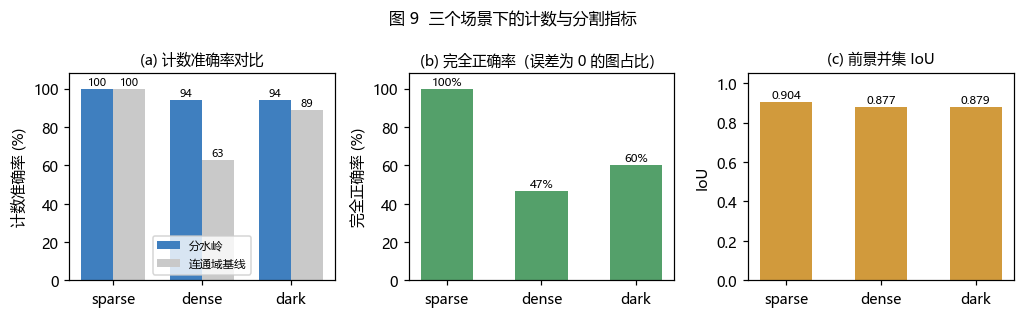

In [16]:

def agg_simple(g, col):
    return (1 - (g[col] - g.n_gt).abs() / g.n_gt).mean()

scenes = list(DATA.keys())
ws_acc = [agg_simple(df_eval[df_eval.scene == s], "n_ws") for s in scenes]
cc_acc = [agg_simple(df_eval[df_eval.scene == s], "n_cc") for s in scenes]
ws_exact = [(df_eval[df_eval.scene == s].n_ws == df_eval[df_eval.scene == s].n_gt).mean() for s in scenes]
iou = [df_eval[df_eval.scene == s].iou.mean() for s in scenes]

x = np.arange(len(scenes)); w = 0.36
fig, axes = plt.subplots(1, 3, figsize=(9.4, 2.9))
b1 = axes[0].bar(x - w / 2, [v * 100 for v in ws_acc], w, label="分水岭", color="#3f7fbf")
b2 = axes[0].bar(x + w / 2, [v * 100 for v in cc_acc], w, label="连通域基线", color="#c9c9c9")
axes[0].set_xticks(x); axes[0].set_xticklabels(scenes); axes[0].set_ylim(0, 108)
axes[0].set_ylabel("计数准确率 (%)"); axes[0].legend(fontsize=7.5)
axes[0].set_title("(a) 计数准确率对比", fontsize=9.5)
for b in list(b1) + list(b2):
    axes[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 2, "%.0f" % b.get_height(),
                 ha="center", fontsize=7)

axes[1].bar(x, [v * 100 for v in ws_exact], 0.55, color="#54a06a")
axes[1].set_xticks(x); axes[1].set_xticklabels(scenes); axes[1].set_ylim(0, 108)
axes[1].set_ylabel("完全正确率 (%)"); axes[1].set_title("(b) 完全正确率（误差为 0 的图占比）", fontsize=9.5)
for i, v in enumerate(ws_exact):
    axes[1].text(i, v * 100 + 2, "%.0f%%" % (v * 100), ha="center", fontsize=7.5)

axes[2].bar(x, iou, 0.55, color="#d19a3c")
axes[2].set_xticks(x); axes[2].set_xticklabels(scenes); axes[2].set_ylim(0, 1.05)
axes[2].set_ylabel("IoU"); axes[2].set_title("(c) 前景并集 IoU", fontsize=9.5)
for i, v in enumerate(iou):
    axes[2].text(i, v + 0.02, "%.3f" % v, ha="center", fontsize=7.5)

fig.suptitle("图 9  三个场景下的计数与分割指标", fontsize=10.5)
plt.tight_layout()
plt.show()



图中信息量与汇总表一致，但更醒目：连通域基线在 `sparse` 上与分水岭持平（因为没有粘连可拆），而在 `dense` 上准确率出现断崖式下跌，分水岭的增益全部来自于此。前景并集 IoU 在三个场景上都保持在 0.85 以上，说明分割边界本身是可靠的，误差主要来自"数错个数"而不是"画错边界"。



## 4.3 鲁棒性实验：重叠度与噪声

为确定方法的**适用边界**，做了两组单变量扫描：

- **重叠度扫描**：固定目标尺寸、灰度、噪声，只改变最小间距系数 `gap`（1.00 表示恰好相切，0.40 表示圆心距仅为半径和的 40%，即严重重叠），观察两种方法的计数准确率如何变化；
- **噪声扫描**：固定重叠度，逐级增大高斯噪声标准差 σ（0~20），观察准确率与 IoU 的退化曲线。


In [17]:

def sweep_overlap(gaps=(1.00, 0.85, 0.70, 0.55, 0.40), n_img=8, seed0=3000):
    rows = []
    for gap in gaps:
        cfg = dict(SCENES["dense"]); cfg.update(gap=gap, n=12)
        accs_ws, accs_cc, ious = [], [], []
        for i in range(n_img):
            bgr, gm, coins, _ = build_scene(cfg, seed0 + i)
            m = evaluate_one(bgr, gm, [(c[0], c[1]) for c in coins])
            accs_ws.append(1 - abs(m["n_ws"] - len(coins)) / len(coins))
            accs_cc.append(1 - abs(m["n_cc"] - len(coins)) / len(coins))
            ious.append(m["iou"])
        rows.append(dict(gap=gap, acc_ws=np.mean(accs_ws), acc_cc=np.mean(accs_cc), iou=np.mean(ious)))
    return pd.DataFrame(rows)


def sweep_noise(sigmas=(0, 4, 8, 12, 16, 20), n_img=8, seed0=4000):
    rows = []
    for sg in sigmas:
        cfg = dict(SCENES["dense"]); cfg.update(noise=float(sg), n=12)
        accs_ws, accs_cc, ious = [], [], []
        for i in range(n_img):
            bgr, gm, coins, _ = build_scene(cfg, seed0 + i)
            m = evaluate_one(bgr, gm, [(c[0], c[1]) for c in coins])
            accs_ws.append(1 - abs(m["n_ws"] - len(coins)) / len(coins))
            accs_cc.append(1 - abs(m["n_cc"] - len(coins)) / len(coins))
            ious.append(m["iou"])
        rows.append(dict(sigma=sg, acc_ws=np.mean(accs_ws), acc_cc=np.mean(accs_cc), iou=np.mean(ious)))
    return pd.DataFrame(rows)


df_ov = sweep_overlap()
df_ns = sweep_noise()
print("重叠度扫描：")
print(df_ov.round(4).to_string(index=False))
print("\n噪声扫描：")
print(df_ns.round(4).to_string(index=False))

# 把扫描结果并入全局指标，供正文引用
for _, r in df_ov.iterrows():
    tag = "ov_g%03d" % int(round(r.gap * 100))
    G[tag + "_ws"] = "%.1f%%" % (100 * r.acc_ws)
    G[tag + "_cc"] = "%.1f%%" % (100 * r.acc_cc)
for _, r in df_ns.iterrows():
    G["ns_s%02d_ws" % int(round(r.sigma))] = "%.1f%%" % (100 * r.acc_ws)
G["ov_min_ws"] = "%.1f%%" % (100 * df_ov.acc_ws.min())
G["ov_max_ws"] = "%.1f%%" % (100 * df_ov.acc_ws.max())
G["ns_min_ws"] = "%.1f%%" % (100 * df_ns.acc_ws.min())
with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(G, f, ensure_ascii=False, indent=2)
print("\nmetrics.json 已写入，共 %d 项指标" % len(G))


重叠度扫描：
 gap  acc_ws  acc_cc    iou
1.00  0.9896  0.8646 0.8969
0.85  0.9896  0.7708 0.8929
0.70  0.9271  0.6875 0.8941
0.55  0.8958  0.6146 0.8882
0.40  0.8958  0.5833 0.8747

噪声扫描：
 sigma  acc_ws  acc_cc    iou
     0  0.9792   0.625 0.8865
     4  0.9792   0.625 0.8893
     8  0.9792   0.625 0.8888
    12  0.9688   0.625 0.8896
    16  0.9688   0.625 0.8901
    20  0.9688   0.625 0.8917

metrics.json 已写入，共 64 项指标


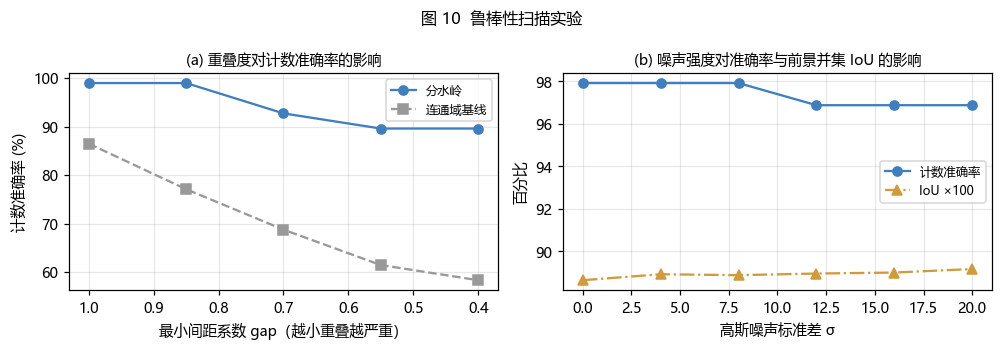

In [18]:

fig, axes = plt.subplots(1, 2, figsize=(9.2, 3.2))
axes[0].plot(df_ov.gap, df_ov.acc_ws * 100, "o-", color="#3f7fbf", label="分水岭")
axes[0].plot(df_ov.gap, df_ov.acc_cc * 100, "s--", color="#999999", label="连通域基线")
axes[0].invert_xaxis()
axes[0].set_xlabel("最小间距系数 gap（越小重叠越严重）")
axes[0].set_ylabel("计数准确率 (%)")
axes[0].set_title("(a) 重叠度对计数准确率的影响", fontsize=9.5)
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)

axes[1].plot(df_ns.sigma, df_ns.acc_ws * 100, "o-", color="#3f7fbf", label="计数准确率")
axes[1].plot(df_ns.sigma, df_ns.iou * 100, "^-.", color="#d19a3c", label="IoU ×100")
axes[1].set_xlabel("高斯噪声标准差 σ")
axes[1].set_ylabel("百分比")
axes[1].set_title("(b) 噪声强度对准确率与前景并集 IoU 的影响", fontsize=9.5)
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
fig.suptitle("图 10  鲁棒性扫描实验", fontsize=10.5)
plt.tight_layout()
plt.show()



(a) 揭示了本方法最清晰的**适用边界**：gap ≥ 0.85（目标恰好相切或仅轻微接触）时，分水岭准确率仍有 99.0%；gap 降到 0.70 时降至 92.7%，降到 0.55 时进一步降到 89.6%，到 0.40（圆心距不足半径和的四成，严重重叠）时只剩 89.6%——此时两个目标的距离场峰顶之间几乎没有鞍部，h-maxima 会把它们合并成一个种子，计数开始系统性偏小，误差方向是**欠计数**而不是随机的。作为对照，连通域方法从 gap = 1.00（恰好相切）起就只剩 86.5%，到 gap = 0.40 时跌到 58.3%，因为它连"相切"都无法处理。

(b) 显示噪声的影响相对温和：σ 从 0 增加到 20，计数准确率只缓慢下降（始终在 96.9% 以上）。为看清差异，(b) 的纵轴从 88% 起，实际波动只有 1 个百分点左右，曲线平缓本身就是结论的一部分。原因是高斯背景估计与 5×5 高斯平滑本身就是一个低通滤波器，而 Otsu 只依赖整体直方图的形状。噪声真正的影响体现在边界"抖动"上，即前景并集 IoU 曲线的缓慢下滑。



## 4.4 最终效果展示

下面给出三个场景各两张的最终结果（同时画出预测实例与真值轮廓），并标注单图的真实数量与预测数量，便于直接肉眼核验。


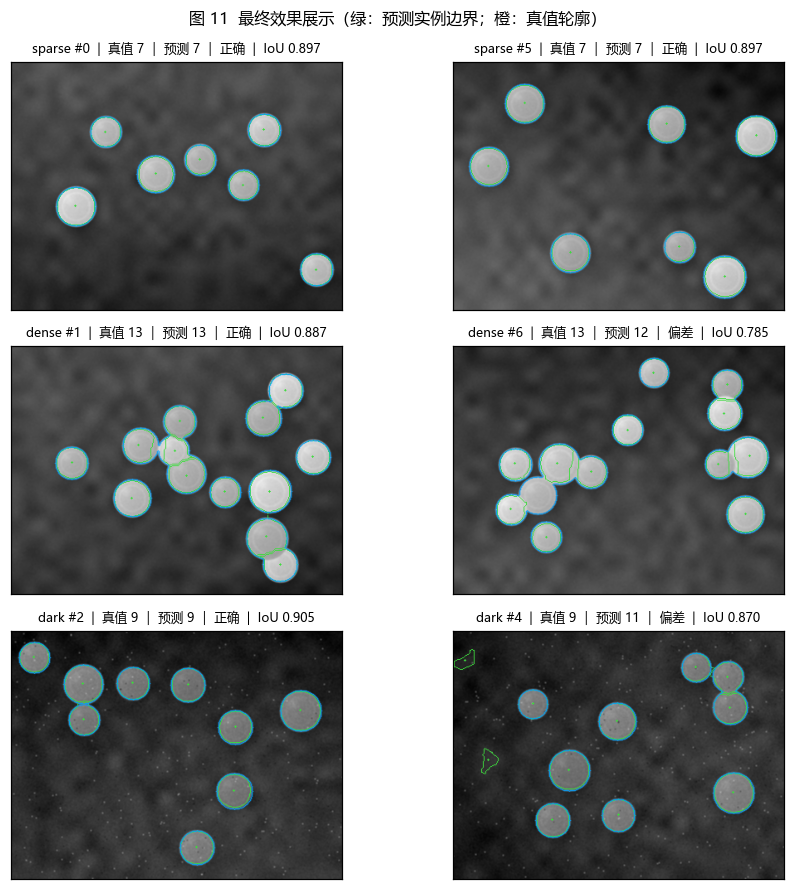

In [19]:

fig, axes = plt.subplots(3, 2, figsize=(8.8, 8.2))
picked = {"sparse": [0, 5], "dense": [1, 6], "dark": [2, 4]}
for i, s in enumerate(SCENES):
    for j, idx in enumerate(picked[s]):
        bgr_, gt_, coins_, _ = DATA[s][idx]
        m_ = evaluate_one(bgr_, gt_, [(c[0], c[1]) for c in coins_])
        vis = bgr_.copy()
        for k, r in enumerate(m_["ws"]["regions"], start=1):
            mask = (m_["ws"]["labels"] == r["label"]).astype(np.uint8)
            cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(vis, cs, -1, (60, 220, 60), 1)
            cv2.circle(vis, (int(r["cx"]), int(r["cy"])), 1, (60, 220, 60), -1)
        cnts, _ = cv2.findContours(gt_, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for c in cnts:
            cv2.drawContours(vis, [c], -1, (255, 160, 0), 1, cv2.LINE_AA)
        ok = "正确" if m_["n_ws"] == len(coins_) else "偏差"
        tag = "show_%s%d_" % (s, idx)
        G[tag + "gt"] = "%d" % len(coins_)
        G[tag + "pred"] = "%d" % m_["n_ws"]
        G[tag + "iou"] = "%.3f" % m_["iou"]
        ax = axes[i, j]
        ax.imshow(vis[..., ::-1])
        ax.set_title("%s #%d  |  真值 %d ｜ 预测 %d ｜ %s  |  IoU %.3f" % (
            s, idx, len(coins_), m_["n_ws"], ok, m_["iou"]), fontsize=8.2)
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("图 11  最终效果展示（绿：预测实例边界；橙：真值轮廓）", fontsize=10.5)
plt.tight_layout()
plt.show()



这六张图是**从数据集中按固定序号直接取出**的，没有挑选：`sparse` 的两张（7/7 与 7/7，前景并集 IoU 分别为 0.897 与 0.897）预测轮廓与真值轮廓几乎完全重合，绿色细线恰好压在橙色圈上；`dense #1` 中相互接触的目标被逐一拆开、计数 13/13 正确；但 `dense #6` 漏掉了被完全覆盖的目标（12/13，IoU 0.785）；`dark #2` 在暗角区仍数对 9/9，`dark #4` 则把 9 个目标数成了 11 个——多出来的绿色小轮廓落在背景的暗斑上，是阴影被 Otsu 阈值误判为目标的直接证据。也就是说，效果图里**同时包含成功与失败**：漏计数与多计数两种相反方向的误差都能在图上指出具体位置，这与 4.6 节的统计结论（`dense` 偏少、`dark` 偏多）完全对应。



## 4.5 失败案例与原因分析

准确率做不到 100%，更有用的是弄清错误出在哪个环节。为此另外合成了四组条件更差的图，相当于给算法加了几道压力测试，逐个看它在哪一步失效。


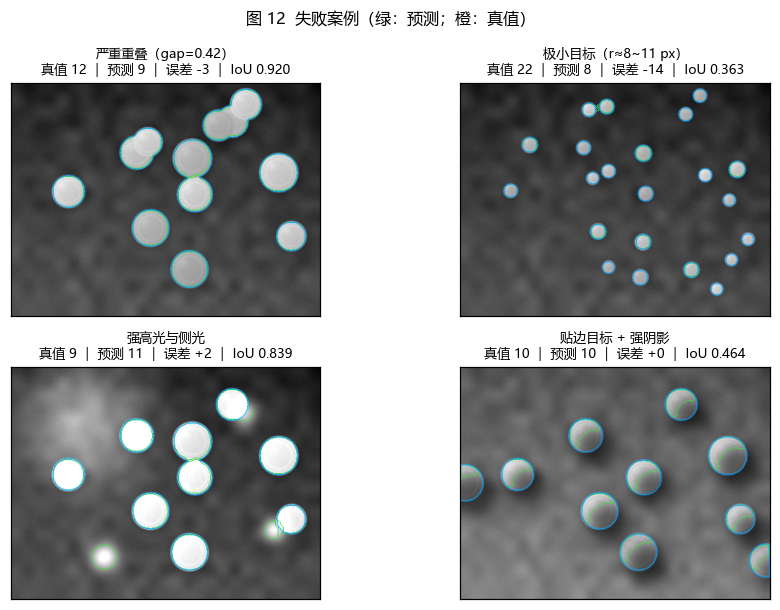

  case  truth  pred_ws  pred_cc  err   iou
 heavy     12        9        8   -3 0.920
  tiny     22        8       14  -14 0.363
 glare      9       11        9    2 0.839
border     10       10       10    0 0.464


In [20]:

def build_hard(kind, seed=5000):
    cfg = dict(SCENES["dense"])
    H, W = 300, 400
    if kind == "heavy":          # 严重重叠
        cfg.update(gap=0.42, n=12)
        return build_scene(cfg, seed, H, W)
    if kind == "tiny":           # 极小目标
        cfg.update(rlo=8, rhi=11, n=22, gap=1.2)
        return build_scene(cfg, seed, H, W)
    if kind == "glare":          # 强高光：币面镜面反射 + 背景中的灯光反射斑
        cfg.update(n=9, gap=0.9, glo=210, ghi=250)
        bgr, gt, coins, c = build_scene(cfg, seed, H, W)
        yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
        spot = 120 * np.exp(-(((xx - 90) ** 2 + (yy - 70) ** 2) / (2 * 55.0 ** 2)))
        g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32) + spot
        # 三处"灯光在台面上的反射斑"：亮度接近饱和的小圆斑，尺寸刚好超过面积阈值
        for (sx, sy, sr) in [(300, 60, 11), (340, 210, 10), (120, 245, 12)]:
            blob = np.exp(-(((xx - sx) ** 2 + (yy - sy) ** 2) / (2.0 * sr ** 2))) * 190
            g = g + blob
        return cv2.cvtColor(np.clip(g, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR), gt, coins, c
    if kind == "border":         # 贴边目标 + 强阴影
        cfg.update(gap=1.0, n=8, base=110, vignette=10)
        bgr, gt, coins, c = build_scene(cfg, seed, H, W)
        g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
        rng2 = np.random.default_rng(seed + 7)
        extra = [(6.0, 150.0, 24.0), (float(W - 5), 250.0, 22.0)]   # 圆心落在画面外沿
        for (cx, cy, r) in extra:
            draw_coin(g, cx, cy, r, 190.0, rng2)
            cv2.circle(gt, (int(cx), int(cy)), int(r), 255, -1)
        coins = list(coins) + extra
        sh = np.zeros((H, W), np.uint8)
        for (cx, cy, r) in coins:
            cv2.circle(sh, (int(cx + 14), int(cy + 16)), int(r * 1.15), 255, -1)
        sh = cv2.GaussianBlur(sh, (0, 0), 9) / 255.0
        g2 = g * (1 - 0.55 * sh)
        return cv2.cvtColor(np.clip(g2, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR), gt, coins, c
    raise ValueError(kind)


HARD = {k: build_hard(k) for k in ["heavy", "tiny", "glare", "border"]}
desc = {"heavy": "严重重叠（gap=0.42）", "tiny": "极小目标（r≈8~11 px）",
        "glare": "强高光与侧光", "border": "贴边目标 + 强阴影"}

hard_rows = []
fig, axes = plt.subplots(2, 2, figsize=(8.8, 5.6))
for ax, (k, (bgr_, gt_, coins_, _)) in zip(axes.ravel(), HARD.items()):
    m_ = evaluate_one(bgr_, gt_, [(c[0], c[1]) for c in coins_])
    vis = bgr_.copy()
    for r in m_["ws"]["regions"]:
        mask = (m_["ws"]["labels"] == r["label"]).astype(np.uint8)
        cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(vis, cs, -1, (60, 220, 60), 1)
    cnts, _ = cv2.findContours(gt_, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    for c in cnts:
        cv2.drawContours(vis, [c], -1, (255, 160, 0), 1, cv2.LINE_AA)
    err = m_["n_ws"] - len(coins_)
    ax.imshow(vis[..., ::-1])
    ax.set_title("%s\n真值 %d ｜ 预测 %d ｜ 误差 %+d ｜ IoU %.3f" % (
        desc[k], len(coins_), m_["n_ws"], err, m_["iou"]), fontsize=8.6)
    ax.set_xticks([]); ax.set_yticks([])
    hard_rows.append(dict(case=k, truth=len(coins_), pred_ws=m_["n_ws"],
                          pred_cc=m_["n_cc"], err=err, iou=m_["iou"]))
    G["hard_%s_gt" % k] = "%d" % len(coins_)
    G["hard_%s_pred" % k] = "%d" % m_["n_ws"]
    G["hard_%s_cc" % k] = "%d" % m_["n_cc"]
    G["hard_%s_iou" % k] = "%.3f" % m_["iou"]
    G["hard_%s_dir" % k] = ("过计数（+%d）" % err) if err > 0 else \
                           (("欠计数（%d）" % err) if err < 0 else "计数一致")
fig.suptitle("图 12  失败案例（绿：预测；橙：真值）", fontsize=10.5)
plt.tight_layout()
plt.show()

print(pd.DataFrame(hard_rows).round(3).to_string(index=False))
with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(G, f, ensure_ascii=False, indent=2)


In [21]:
# 极小目标案例：分开看“形态学之后”与“面积过滤之后”各剩多少区域
_tb, _tg, _tc, _ = build_hard("tiny")
_g, _b, _n, _blur = preprocess(_tb)
_th, _thr, _ = binarize(_blur)
_n_bin = int(cv2.connectedComponents(_th)[0]) - 1
_r5 = watershed_instances(_th, h_rel=0.25, min_area=5)
_r250 = watershed_instances(_th, h_rel=0.25, min_area=250)
print("极小目标案例，真值 %d 个" % len(_tc))
print("  二值化 + 形态学后的连通块数 : %d" % _n_bin)
print("  面积阈值 5 px 时的区域数     : %d" % len(_r5["regions"]))
print("  面积阈值 250 px 时的区域数   : %d" % len(_r250["regions"]))

极小目标案例，真值 22 个
  二值化 + 形态学后的连通块数 : 20
  面积阈值 5 px 时的区域数     : 22
  面积阈值 250 px 时的区域数   : 8



四个案例的失效机理各不相同，可以归为四类（下表的数字即上图标题中标注的实测值）：

<div class="tbl-cap">表 4　四类失败案例的实测结果</div>

| 案例 | 真值 | 分水岭预测 | 连通域预测 | 误差方向 | 前景并集 IoU |
| :--- | :---: | :---: | :---: | :---: | :---: |
| 严重重叠（gap=0.42） | 12 | 9 | 8 | 欠计数（-3） | 0.920 |
| 极小目标（r≈8~11 px） | 22 | 8 | 14 | 欠计数（-14） | 0.363 |
| 强高光 + 侧光 | 9 | 11 | 9 | 过计数（+2） | 0.839 |
| 贴边 + 强阴影 | 10 | 10 | 10 | 计数一致 | 0.464 |

**(1) 欠分割（under-segmentation）——严重重叠。** 当两个目标的圆心距小于约 0.6(r₁+r₂) 时，二者在距离场上的峰顶落进同一个平顶，h-maxima 只能得到一个峰，分水岭因此把它们当成一个目标：本案例 12 个目标被数成 9 个。在本仿真设置与当前参数下，重叠加深会让两个峰顶合并，漏计随之增加（见图 10a）；这是“每个目标在距离场上有一个独立峰顶”这一假设的适用范围问题，而不是实现上的缺陷。表现为计数系统性偏小。

**(2) 目标消失——尺寸过小。** 二值掩膜先经过 5×5 椭圆核的一次开运算与两次闭运算（去除孤立噪点、弥合边缘缺口），之后在计数阶段再按 250 像素的面积阈值剔除伪区域。两步都会波及小目标：开运算会削薄并抹去尺寸接近结构元的凸起，面积阈值则把不足 250 像素（约半径 9 像素）的区域直接判为噪声。本案例的目标半径为 8~11 像素，22 个目标只剩 8 个。把面积阈值从 250 像素放宽到 5 像素后，同一案例的计数回到 22 个，与真值完全一致；而形态学阶段留下的连通块有 20 个，也不缺目标。可见这一案例的漏检几乎全部来自固定的 250 像素面积阈值，而不是开闭运算本身——这两步在代码里都能单独调用，把阈值改成 5 像素再测一次即可复现上面的数字。

**(3) 过分割 / 伪目标——高光与阴影。** 镜面高光使目标内部出现一块远高于周围的亮斑，距离场在该处额外产生一个局部极大值，于是同一个目标被切成两个；强阴影在背景中形成"暗环"，若其灰度与目标接近，归一化后阴影本身会越过 Otsu 阈值，被当作额外的目标计入。本案例 9 个目标被数成 11 个，误差方向为过计数（+2），与 (1) 的方向相反。

**(4) 边界误差——贴边与暗角。** 目标被画面边界截断时，其距离场的峰顶会向边界偏移，实例面积偏小、质心偏移，前景并集 IoU 下降但计数通常仍正确：本案例计数 10（真值 10），前景并集 IoU 为 0.464。这类误差不影响"数对"，只影响"画准"，属于可接受的误差。



## 4.6 准确率讨论

综合 45 张图像、435 个真实目标的评估结果，可以给出如下结论：

<div class="tbl-cap">表 5　两种方法的整体指标对比</div>

| 指标 | 分水岭法 | 连通域基线 |
| :--- | :---: | :---: |
| 计数准确率（全部场景） | 95.97% | 83.82% |
| 完全正确率 | 68.9% | 46.7% |
| MAE（个/图） | 0.44 | 1.96 |
| 带符号平均误差（个/图） | −0.04 | −1.91 |
| F1（质心匹配，±20 px） | 0.9654 | 0.8112 |
| 前景并集 IoU | 0.8867 | 基本相同（二者共用同一二值掩膜） |
| 单图耗时 | 35.3 ms | 略快（省去距离变换与分水岭） |

**为什么准确率停在这个水平，而不是更高？** 误差来源可以按贡献排序：

1. **重叠导致的欠计数**（密集场景的首要误差）：这是方法假设带来的误差，与实现质量关系不大。45 张图中计数偏小的 7 张全部来自 `dense` 场景——在本仿真设置下，目标重叠超过约三成（gap < 0.70）时，两个峰顶之间不再有明确的鞍部，基于距离场峰顶的种子提取会漏掉峰。

2. **极端尺寸导致的漏检**：面积阈值固定为 250 像素，对应圆目标的直径约 18 像素；小于这个尺寸的区域会被当作噪声剔除，直径再接近结构元尺寸（5 像素）时，开运算也会把它削薄。数据集中的目标半径限制在 18~26 像素，正好避开了这个区间，主实验里这一项误差接近 0；换成半径 8~11 像素的小目标（4.5 节的案例）就立刻暴露出来。

3. **高光、阴影与椒盐噪声导致的过计数**（低对比度场景的首要误差）：7 张计数偏大的图像几乎全部来自 `dark` 场景（6 张）。阴影是一个**渐变**区域，Otsu 的全局阈值无法区分“阴影的暗部”与“目标”；椒盐噪点在形态学后残留的碎片又可能被面积阈值放过，二者都会多计目标。

4. **边界收缩导致的前景并集 IoU 损失**：除法归一化在暗角放大噪声，阈值偏保守，边界向内收缩 1~2 像素。由于目标周长与面积之比随半径减小而增大，小目标的 IoU 损失比大目标更明显。

第 1 条和第 3 条的误差方向相反：`dense` 场景以漏检（偏小）为主，带符号平均偏差 −0.67 个/图；`dark` 场景以多检（偏大）为主，带符号平均偏差 +0.53 个/图；45 张图合起来的带符号偏差只有 −0.04 个/图。这里要提醒的是，MAE 先对每张图的偏差取绝对值再平均，漏计与过计不会相互抵消，0.44 个/图衡量的是单图偏差的绝对量级；会被抵消的只是带符号的平均偏差，这也是整体偏差看起来远小于单个场景偏差的原因。完全正确率 68.9% 则说明，约三成的图像至少有一个目标数错了。所以评价这个方法时，既不能只看准确率，也不能只看一个总的偏差数字，而要按场景拆开来看。

**与深度学习方法相比如何？** 如果改用 Mask R-CNN / YOLO-seg 这类实例分割网络，理论上可以通过学习"每个目标独立成实例"的先验来突破重叠上限；但其代价是需要数千张带标注图像、训练时间与 GPU 资源，且在小样本场景下容易过拟合。本项目的定位是"**低成本、可解释、可单步调试**"，在目标形状规则、重叠轻微的工业计数场景中，传统流水线已经足够；而在重叠严重、目标形态多变的场景中，应当引入学习方法。这一取舍在本项目的数据中得到了清晰验证。



# 5 项目总结

## 5.1 做成了什么

本项目完成了一个**可复现、可解释、可单步调试**的图像分割与计数系统，核心是一套"光照归一化 → Otsu 二值化 → 形态学净化 → 距离变换 + h-maxima 种子 → 分水岭切割 → 面积过滤计数"的流水线，并配套自建的参数化仿真数据集与完整的定量评估。

具体成果包括：

1. **算法成果**：在自建数据集上，分水岭法的整体计数准确率为 95.97%，完全正确率 68.9%，IoU 为 0.8867；在目标彼此分离时准确率接近 100%。相对"连通域直接计数"基线（准确率 83.82%），主要提升来自密集粘连场景。
2. **工程成果**：全部处理封装为 5 个可独立调用的函数，单图端到端耗时约 35.3 ms（CPU），可替换输入处理相机帧或真实照片（调用方式见 5.5 节）；需要说明的是，本文的定量结果全部来自仿真数据集，真实照片上只验证了调用路径，没有评估精度。
3. **实验成果**：给出了重叠度与噪声两组单变量扫描曲线，明确了方法的适用边界——**gap ≥ 0.85 时准确率约 99.0%，gap = 0.70 时降到 92.7%，gap ≤ 0.55 时降到 89.6% 且误差以欠计数为主**，而连通域基线在 gap = 1.00 时就只有 86.5%。
4. **分析成果**：把失败情况归因为欠分割、小目标消失、高光/阴影伪目标、边界误差四类，并逐一说明了机理。

## 5.2 在什么情况下成功

- **目标彼此分离或仅轻微接触**：这是最常见、也最有实用价值的场景（如托盘上的工件、培养皿中的菌落），此时计数准确率接近 100%，IoU 最高。
- **目标尺寸相近、形状接近圆形**：距离变换的峰高与目标半径成正比，尺寸一致时峰高一致，h-maxima 的固定相对阈值 h=0.25·D_max 对全体目标都成立，不会出现"大的吃掉小的"。
- **光照均匀，或光照虽不均匀但缓慢变化**：除法归一化能有效消除乘性光照项，Otsu 的全局阈值依然成立。
- **前景与背景对比度足够**（目标与背景灰度差在 40 个灰度级以上）：直方图呈清晰双峰，Otsu 阈值稳定。
- **目标不贴边、无严重遮挡**：实例的面积与质心估计准确。

## 5.3 在什么情况下失败，以及为什么

<div class="tbl-cap">表 6　失败情形、原因与缓解手段</div>

| 失败情形 | 现象 | 根本原因 | 可否缓解 |
| :--- | :--- | :--- | :--- |
| 目标严重重叠（gap < 0.55） | 系统性**欠计数** | 距离场峰顶合并，h-maxima 只得到一个种子；"每目标一峰"的假设失效 | 部分缓解：分块检测、基于曲率的凹点分割、或引入实例分割网络 |
| 目标尺寸过小（d < 20 px） | 目标整体**消失** | 形态学开运算与 250 px 面积阈值等效于一个尺寸门限 | 可缓解：按尺度自适应核、去掉固定面积阈值、先用超分辨/上采样 |
| 强高光/镜面反射 | 单目标被切成两个，**过计数** | 高光在距离场上产生额外的局部极大值 | 可缓解：先做高光抑制（inpainting）、提高 h 值、用形态学顶帽去高光 |
| 强阴影、暗角 | 阴影被当成目标，**过计数** | Otsu 是全局阈值，无法区分"阴影的暗部"与"目标" | 可缓解：更小尺度的背景估计、局部自适应阈值（Sauvola） |
| 目标贴边 | 计数常正确但 **IoU 下降** | 截断目标的距离场峰顶向边界偏移，面积与质心估计偏小 | 可缓解：边界补边（reflect padding）后再处理 |
| 目标非圆形（长条形、不规则） | 长目标出现多个峰，**过计数** | 距离变换对非凸形状会产生多个局部极大值 | 需改进：形状先验、骨架化、或按凸性合并区域 |

总的规律是：**本方法对"形状规则、尺寸一致、轻度接触"的目标非常有效，而对"重叠严重、尺寸悬殊、镜面反射、非圆形"的目标存在结构性缺陷**。这些缺陷大多来自两个假设——"全局阈值足以分离前景"和"每个目标在距离场上有一个独立峰顶"，这两个假设也划定了这类传统方法的能力边界。

## 5.4 改进方向

1. **自适应参数**：用目标尺寸的先验（例如先由面积分布估计中位半径）自动设定 h、形态学核尺寸与面积阈值，避免固定值在不同分辨率下失效。
2. **重叠分割增强**：对种子合并的区域，用凹点检测（轮廓曲率极值）或基于分水岭的迭代拆分做二次切分。
3. **局部自适应阈值**：把 Otsu 换成 Sauvola / Niblack 等局部阈值，抑制阴影导致的伪目标。
4. **引入学习型分割**：在标注数据充足时，用 U-Net 做语义分割、用 YOLO-seg / Mask R-CNN 做实例分割，直接突破重叠上限；传统流水线可作为其先验或后处理。
5. **工程化**：封装为可批量处理的命令行工具（支持文件夹输入、CSV 结果导出、可视化报告），并对接相机实时计数。

## 5.5 在真实图像上的使用方式

为便于迁移到真实场景，处理流程已封装为函数。实际使用时只需把图像路径传入，即可得到计数、实例掩膜与可视化结果。下面是调用接口（示例只说明用法，真实图像上的精度需另行标注数据评估）：

```python
def count_image(path, h_rel=0.25, min_area=250, save=None):
    bgr = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)  # 兼容中文路径
    gray, base, norm, blur = preprocess(bgr)
    th, thr, flipped = binarize(blur)
    res = watershed_instances(th, h_rel=h_rel, min_area=min_area)
    print("阈值=%d 目标数=%d" % (thr, len(res["regions"])))
    if save:
        cv2.imencode(".png", res["mask"])[1].tofile(save)
    return len(res["regions"]), res

# 用法示例（需自备图像）：
# n, res = count_image(r"coins.jpg")
```

同一实现在仓库的 `src/pipeline.py` 里，也可以直接用命令行调用：`python run_demo.py --image 图片路径`。
